# Gold 통합 데이터 EDA

- 데이터: `project/data/model_datasets/unified/gold_unified.csv` (4,669행 × 81열)
- 스키마·생성 규칙: `project/md/gold_unified_schema.md`
- 한 행 = 상품 1개, 통합 키 = `출처 + 상품ID`

## 0. 환경 설정

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 (Windows: 맑은 고딕)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 차트 스타일: 옅은 그리드, 얇은 축
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
})

# 출처별 고정 색상 (순위가 아닌 출처에 색을 고정)
SOURCE_ORDER = ["danawa", "zooplus", "petsathome", "petsmart"]
SOURCE_COLOR = dict(zip(SOURCE_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

pd.set_option("display.max_rows", 100)

## 1. 데이터 로드

In [2]:
DATA_PATH = Path("../data/model_datasets/unified/gold_unified.csv")
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
df["출처"] = pd.Categorical(df["출처"], categories=SOURCE_ORDER)
# 수분_pct에는 건식 추정 수분이 채워져 있다 (수분추정여부=True). 실측만 쓰는 분석용으로 따로 둔다.
df["수분_실측_pct"] = df["수분_pct"].mask(df["수분추정여부"] == True)

print(f"행 수: {df.shape[0]:,} / 열 수: {df.shape[1]}")
print(f"통합 키(출처+상품ID) 중복: {df.duplicated(['출처', '상품ID']).sum()}")
df["출처"].value_counts().rename("상품 수").to_frame()

행 수: 4,669 / 열 수: 82
통합 키(출처+상품ID) 중복: 0


,상품 수
출처,
danawa,1830
zooplus,1690
petsathome,670
petsmart,479


## 2. `기능_원문`의 종류

`기능_원문`은 상품에 붙은 건강 기능 라벨의 원문이며, 한 상품에 여러 라벨이 `|`로 이어져 있다 (예: `소화·장건강|피부·모질개선`).
라벨 종류를 세기 위해 라벨 1개 = 1행으로 펼친다.

In [3]:
labels = (df[["출처", "상품ID", "기능_원문"]]
          .assign(라벨=df["기능_원문"].str.split("|"))
          .explode("라벨"))
labels["라벨"] = labels["라벨"].str.strip()

n_labels = df["기능_원문"].str.split("|").str.len()
print(f"고유 라벨 수: {labels['라벨'].nunique()}")
print(f"상품당 라벨 수: 평균 {n_labels.mean():.2f}, 중앙값 {n_labels.median():.0f}, 최대 {n_labels.max()}")

summary = labels.groupby("출처", observed=True).agg(고유_라벨_수=("라벨", "nunique"), 라벨_부착_건수=("라벨", "size"))
summary["상품_수"] = df["출처"].value_counts()
summary["상품당_평균_라벨"] = (summary["라벨_부착_건수"] / summary["상품_수"]).round(2)
shared = labels.groupby("라벨")["출처"].nunique()
print(f"2개 이상 출처에 함께 나오는 라벨: {(shared > 1).sum()}개")
summary

고유 라벨 수: 79
상품당 라벨 수: 평균 1.81, 중앙값 1, 최대 12
2개 이상 출처에 함께 나오는 라벨: 0개


,고유_라벨_수,라벨_부착_건수,상품_수,상품당_평균_라벨
출처,,,,
danawa,16,4301,1830,2.35
zooplus,26,2630,1690,1.56
petsathome,13,803,670,1.20
petsmart,24,710,479,1.48


### 2-1. 출처별 기능 라벨 빈도 (막대그래프)

출처마다 라벨 어휘가 달라 출처별로 그래프를 하나씩 그린다. 막대 길이는 **해당 라벨이 붙은 상품 수**이고, 괄호 안은 **그 출처 Gold 상품 중 비율**이다.
각 그래프는 `figures/` 폴더에 PNG 파일로도 저장한다.

In [4]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

counts = {s: labels.loc[labels["출처"] == s, "라벨"].value_counts() for s in SOURCE_ORDER}
n_products = df["출처"].value_counts()


def plot_label_freq(source):
    vc = counts[source].iloc[::-1]  # 빈도 높은 라벨이 위로
    fig, ax = plt.subplots(figsize=(10, 0.3 * len(vc) + 1.4))
    ax.barh(vc.index, vc.values, color=SOURCE_COLOR[source], height=0.72)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f"  {v:,} ({v / n_products[source] * 100:.1f}%)", va="center", fontsize=8.5, color=INK2)
    ax.set_title(f"{source} 기능_원문 라벨 빈도 (Gold)  ·  라벨 {len(vc)}종, 상품 {n_products[source]:,}개")
    ax.set_xlim(0, vc.max() * 1.22)
    ax.set_xlabel("라벨이 붙은 상품 수")
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    path = FIG_DIR / f"function_label_freq_{source}.png"
    fig.savefig(path, dpi=150)
    plt.show()
    print(f"저장: {path}")

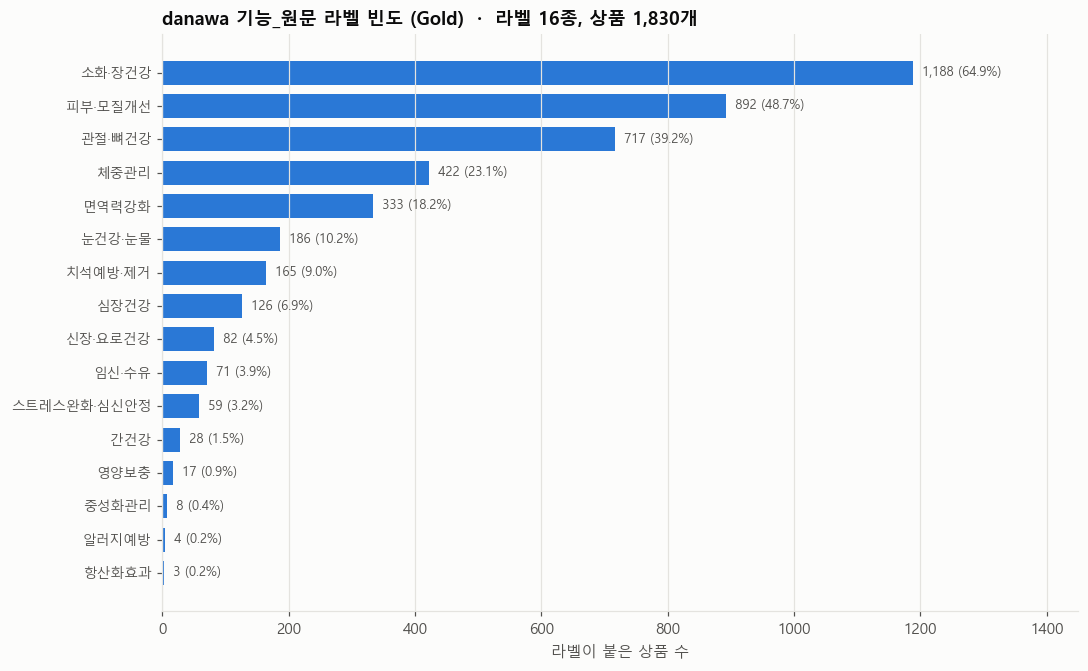

저장: figures\function_label_freq_danawa.png


In [5]:
plot_label_freq("danawa")

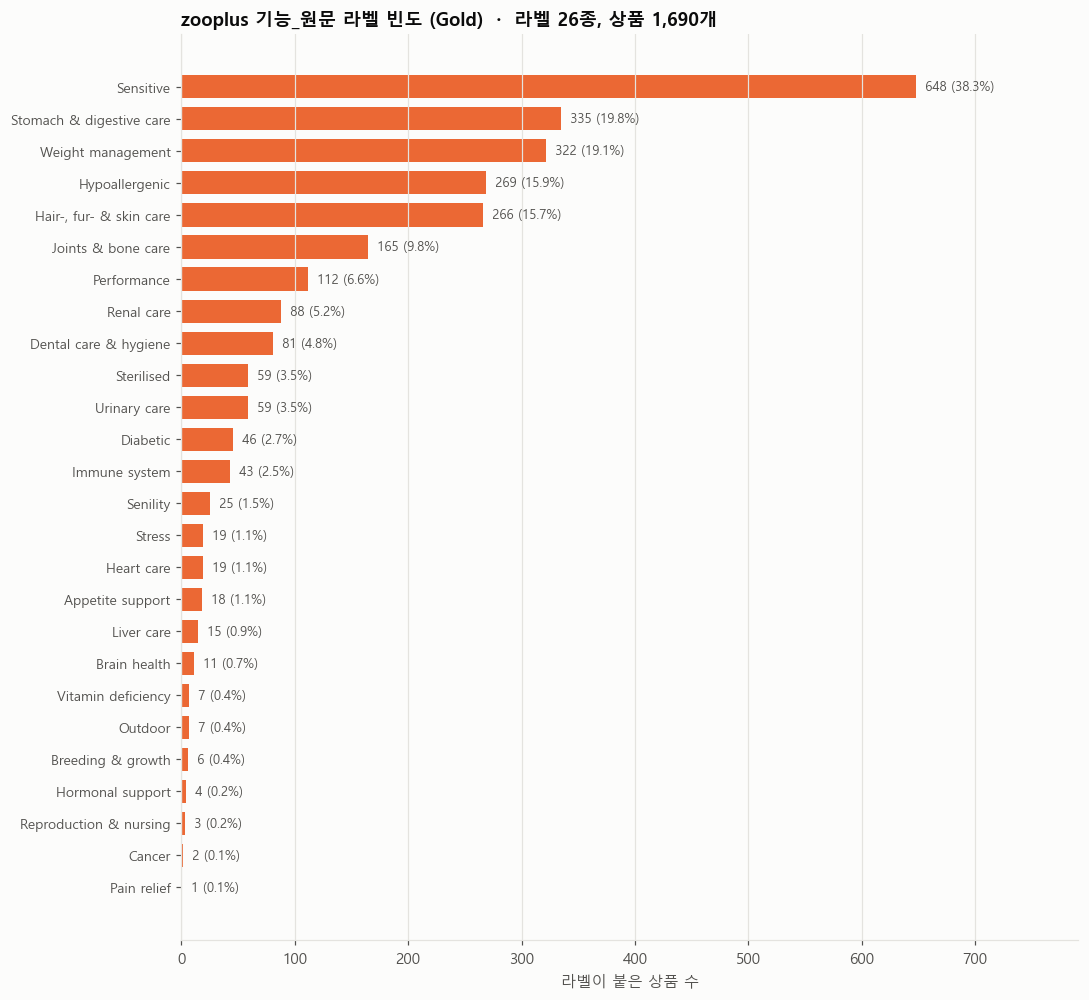

저장: figures\function_label_freq_zooplus.png


In [6]:
plot_label_freq("zooplus")

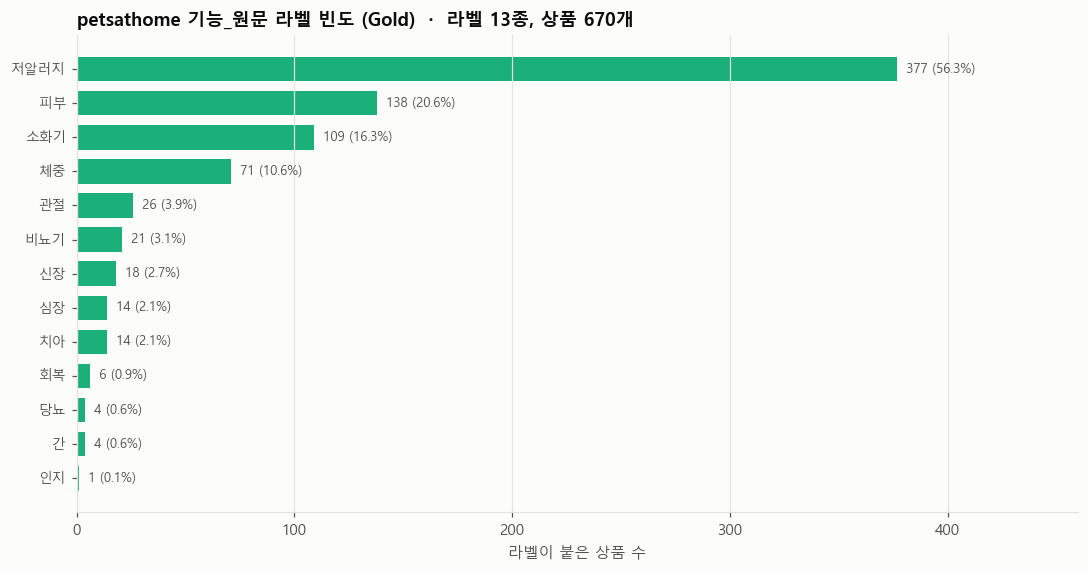

저장: figures\function_label_freq_petsathome.png


In [7]:
plot_label_freq("petsathome")

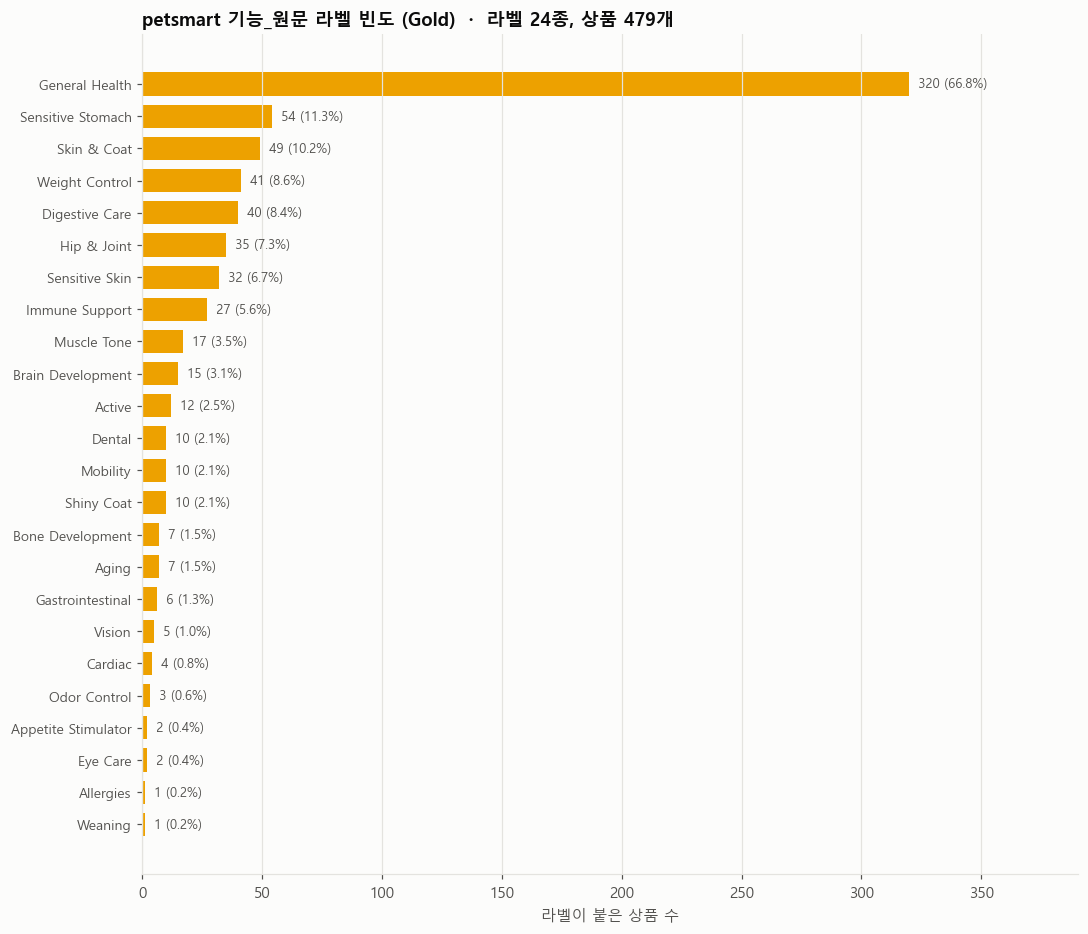

저장: figures\function_label_freq_petsmart.png


In [8]:
plot_label_freq("petsmart")

### 2-2. 전체 라벨 목록

In [9]:
label_table = (labels.groupby(["출처", "라벨"], observed=True).size().rename("상품_수").reset_index()
               .sort_values(["출처", "상품_수"], ascending=[True, False]))
label_table["출처_내_비율_%"] = (label_table["상품_수"] / label_table["출처"].astype(str).map(n_products.to_dict()) * 100).round(1)
label_table.reset_index(drop=True)

,출처,라벨,상품_수,출처_내_비율_%
0,danawa,소화·장건강,1188,64.9
1,danawa,피부·모질개선,892,48.7
2,danawa,관절·뼈건강,717,39.2
3,danawa,체중관리,422,23.1
4,danawa,면역력강화,333,18.2
5,danawa,눈건강·눈물,186,10.2
6,danawa,치석예방·제거,165,9.0
7,danawa,심장건강,126,6.9
8,danawa,신장·요로건강,82,4.5
9,danawa,임신·수유,71,3.9


### 2-3. 관찰

- **라벨 어휘가 출처마다 완전히 다르다.** 79종 중 두 출처 이상에 함께 나오는 라벨은 없다. 같은 개념도 출처별로 이름이 다르다.
  - 소화: `소화·장건강`(다나와) / `Stomach & digestive care`(Zooplus) / `소화기`(Pets at Home) / `Digestive Care`·`Sensitive Stomach`·`Gastrointestinal`(PetSmart)
  - 피부·모질: `피부·모질개선` / `Hair-, fur- & skin care` / `피부` / `Skin & Coat`·`Sensitive Skin`·`Shiny Coat`
  - 관절: `관절·뼈건강` / `Joints & bone care` / `관절` / `Hip & Joint`·`Mobility`·`Bone Development`
- **건강 기능이 아닌 라벨이 상위권에 섞여 있다.** Zooplus `Sensitive`(가장 많음)·`Hypoallergenic`·`Performance`·`Sterilised`, Pets at Home `저알러지`(가장 많음), PetSmart `General Health`(가장 많음)는 식이·대상 특성이나 포괄 태그다. `training_dataset_summary.md`는 이들을 건강 기능 정답과 분리하도록 정했다.
- **빈도가 낮은 라벨이 길게 이어진다.** `Pain relief`, `인지`, `Allergies`, `Weaning`처럼 1~3건인 라벨은 단독으로는 학습할 수 없다.
- 따라서 원문 라벨을 그대로 정답으로 쓸 수 없고, 표준 카테고리(digestive, skin_coat, joint_bone 등)로 묶어야 한다 (3절).

## 3. 표준 카테고리 정리

원문 라벨 79종을 `기능카테고리사전.csv`로 표준 카테고리에 묶고, 학습에 쓸 카테고리를 정량 기준으로 고른다.
매핑 결과는 통합 데이터의 `기능카테고리` 컬럼(건강기능 카테고리 전체)에 들어 있다. 기준의 상세 근거는 `project/md/function_category_criteria.md`에 있다.

**집계 기준**
- 건강기능(`유형=health_function`) 카테고리만 센다. `Sensitive`·`General Health`·`Hypoallergenic` 같은 식이특성·포괄 태그는 정의상 제외한다.
- 동의어를 먼저 합친 뒤, 상품 단위로 센다 (한 상품에 같은 카테고리 원문이 여러 개여도 1건). 신장과 요로는 다나와 원문 `신장·요로건강`이 둘을 구분하지 않으므로 `renal_urinary` 하나로 묶는다.
- 중복 상품(`중복여부=True`)은 제외한다.

**채택 기준: 모비율 신뢰구간**
- 카테고리별 재현율을 5-fold 교차검증으로 추정할 때, 95% 신뢰수준에서 오차가 ±10%p(탐색적 연구 관례) 이내여야 한다.
- 필요한 양성 수: $n = z^2 p(1-p) / E^2 = 1.96^2 \times 0.25 / 0.10^2 \approx 96.04 \rightarrow 97$건
- 5-fold 교차검증은 모든 상품을 한 번씩 평가하므로, 전체 상품 수 $N \ge 97$이면 채택한다.

In [10]:
Z, P, E_MAX = 1.96, 0.5, 0.10    # 신뢰수준 95%, 가장 보수적인 p, 허용 오차 ±10%p
TEST_RATIO_82 = 0.2               # 비교용: 8:2 단일 분할의 테스트 비율
N_MIN = int(np.ceil(Z**2 * P * (1 - P) / E_MAX**2))
print(f"카테고리별 최소 양성 수: {N_MIN}")

dictionary = pd.read_csv("../data/model_datasets/기능카테고리사전.csv", encoding="utf-8-sig")
category_name = dictionary.drop_duplicates("카테고리").set_index("카테고리")["카테고리명"]
print(f"사전에 없는 원문 라벨이 있는 상품: {df['품질플래그'].fillna('').str.contains('기능라벨_사전없음').sum()}개")

health = (df.loc[df["중복여부"] != True, ["출처", "상품ID", "기능카테고리"]].dropna()
          .assign(카테고리=lambda t: t["기능카테고리"].str.split("|")).explode("카테고리"))
health["출처"] = health["출처"].astype(str)
by_source = health.pivot_table(index="카테고리", columns="출처", values="상품ID", aggfunc="size", fill_value=0)
by_source = by_source.reindex(columns=SOURCE_ORDER, fill_value=0)

cat = pd.DataFrame({"상품수": by_source.sum(axis=1)}).sort_values("상품수", ascending=False)
cat.insert(0, "이름", cat.index.map(category_name))
cat["누적비율_%"] = (cat["상품수"].cumsum() / cat["상품수"].sum() * 100).round(1)
cat["출처수"] = (by_source.loc[cat.index] > 0).sum(axis=1)
cat["최대출처비중_%"] = (by_source.loc[cat.index].max(axis=1) / cat["상품수"] * 100).round(0)
cat["오차_5fold"] = (Z * np.sqrt(P * (1 - P) / cat["상품수"])).round(3)
cat["오차_8대2"] = (Z * np.sqrt(P * (1 - P) / (cat["상품수"] * TEST_RATIO_82))).round(3)
cat["판정"] = np.where(cat["상품수"] >= N_MIN, "채택", "보류")
adopted = cat.index[cat["판정"] == "채택"].tolist()
print(f"채택 {len(adopted)}개, 보류 {len(cat) - len(adopted)}개 / 채택 카테고리가 건강기능 라벨의 "
      f"{cat.loc[adopted, '상품수'].sum() / cat['상품수'].sum() * 100:.1f}% 차지")

# 사전의 학습채택(→ 통합 데이터의 학습카테고리)이 이 기준으로 다시 계산한 판정과 같은지 확인
dict_adopted = set(dictionary.loc[dictionary["학습채택"] == "adopted", "카테고리"])
print(f"사전의 학습채택과 일치: {set(adopted) == dict_adopted}")
cat

카테고리별 최소 양성 수: 97
사전에 없는 원문 라벨이 있는 상품: 0개
채택 9개, 보류 8개 / 채택 카테고리가 건강기능 라벨의 97.1% 차지
사전의 학습채택과 일치: True


,이름,상품수,누적비율_%,출처수,최대출처비중_%,오차_5fold,오차_8대2,판정
카테고리,,,,,,,,
digestive,소화·장 건강,1508,27.6,4,79.0,0.025,0.056,채택
skin_coat,피부·모질,1171,49.0,4,76.0,0.029,0.064,채택
joint_bone,관절·뼈,856,64.7,4,84.0,0.033,0.075,채택
weight_management,체중 관리,652,76.6,4,65.0,0.038,0.086,채택
immune,면역,387,83.7,3,86.0,0.050,0.111,채택
dental_oral,치아·구강,221,87.7,4,75.0,0.066,0.147,채택
vision,눈 건강,191,91.2,2,97.0,0.071,0.159,채택
renal_urinary,신장·요로,171,94.3,3,48.0,0.075,0.168,채택
heart,심장,149,97.1,4,85.0,0.080,0.180,채택


### 3-1. 카테고리별 상품 수와 채택 여부

파란 막대가 채택(97건 이상), 회색 막대가 보류다. 점선은 최소 양성 수 97건이다.

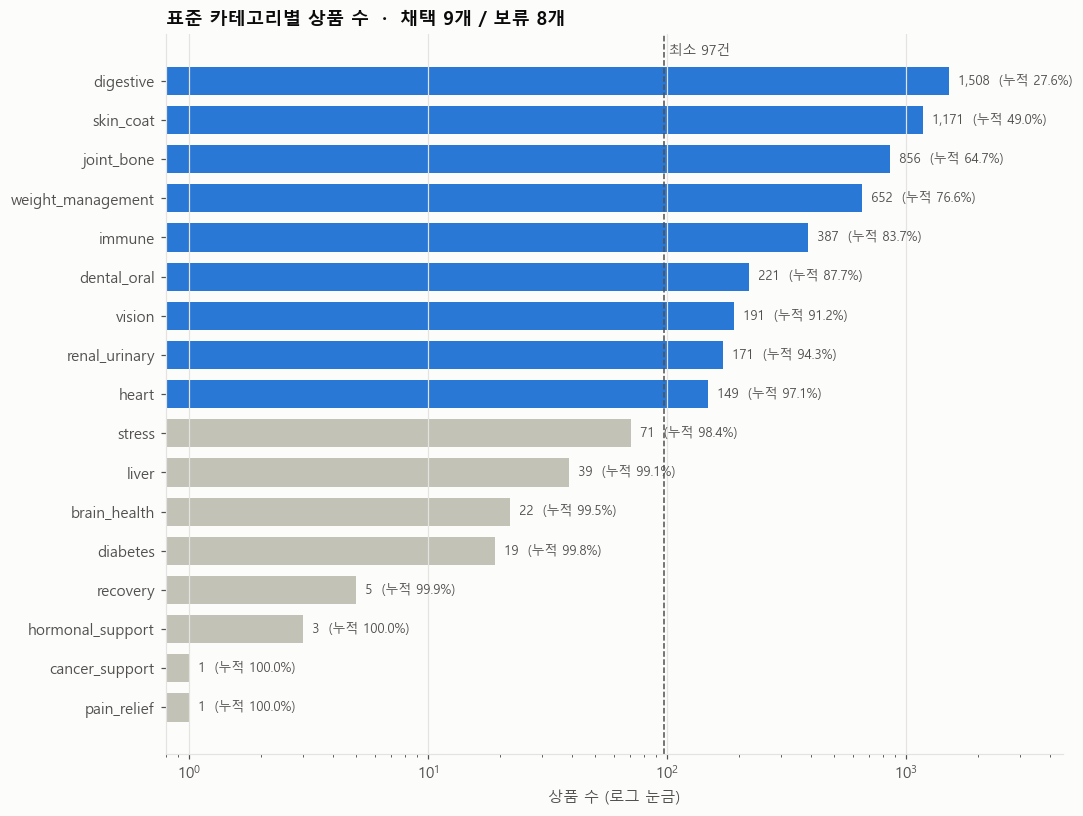

In [11]:
ADOPT, HOLD = "#2a78d6", "#c3c2b7"
vc = cat["상품수"].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.36 * len(vc) + 1.4))
ax.barh(vc.index, vc.values, height=0.72,
        color=[ADOPT if c in adopted else HOLD for c in vc.index])
for y, (c, v) in enumerate(vc.items()):
    ax.text(v, y, f"  {v:,}  (누적 {cat.at[c, '누적비율_%']:.1f}%)", va="center", fontsize=8.5, color=INK2)
ax.axvline(N_MIN, color=INK2, lw=1, ls="--")
ax.text(N_MIN, len(vc) - 0.4, f" 최소 {N_MIN}건", fontsize=9, color=INK2, va="bottom")
ax.set_xscale("log")
ax.set_xlim(0.8, vc.max() * 3)
ax.set_xlabel("상품 수 (로그 눈금)")
ax.set_title(f"표준 카테고리별 상품 수  ·  채택 {len(adopted)}개 / 보류 {len(cat) - len(adopted)}개")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_counts.png", dpi=150)
plt.show()

### 3-2. 카테고리별 신뢰구간 오차

같은 상품 수로 재현율을 추정할 때의 95% 신뢰구간 반폭이다. 5-fold 교차검증은 모든 상품을 평가하고, 8:2 단일 분할은 20%만 평가하므로 오차가 약 2.2배($\sqrt{5}$배) 크다.
점선(±0.10)보다 왼쪽이면 기준 충족이다. 오차가 0.5를 넘는 카테고리는 잘라서 표시했다.

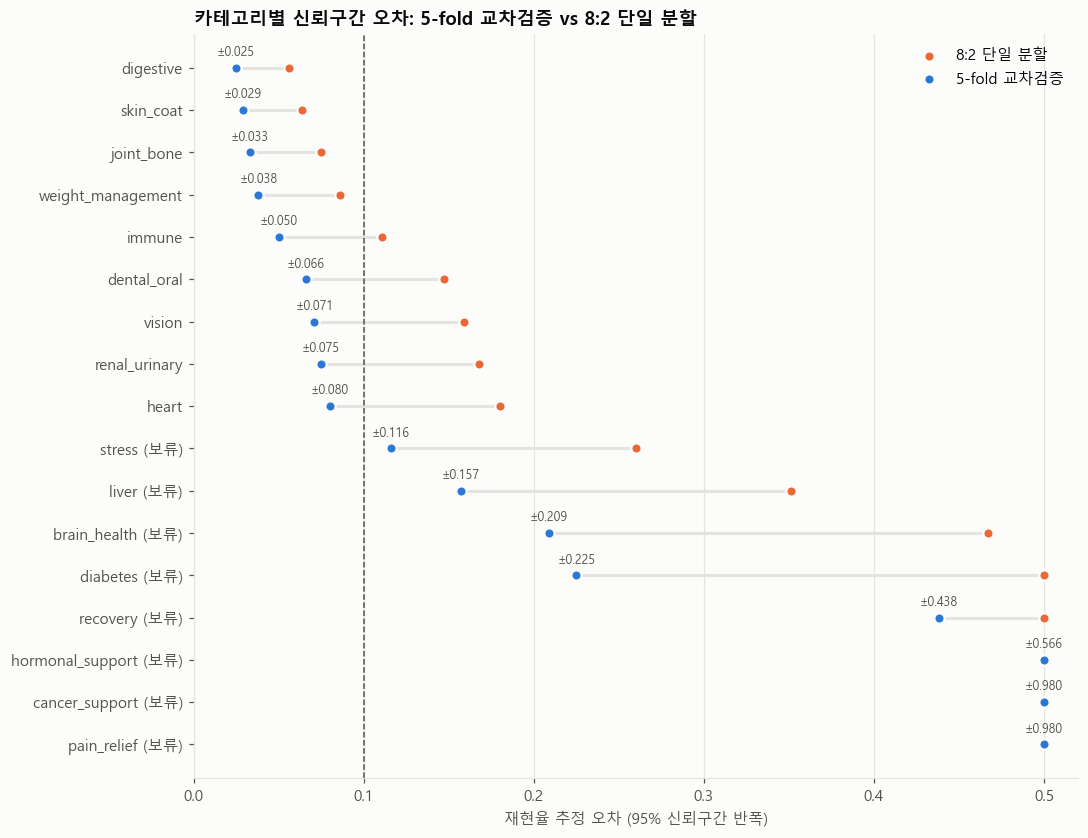

In [12]:
COLOR_CV, COLOR_82 = "#2a78d6", "#eb6834"
err = cat[["오차_5fold", "오차_8대2"]].iloc[::-1]
CLIP = 0.5
fig, ax = plt.subplots(figsize=(10, 0.36 * len(err) + 1.6))
y = np.arange(len(err))
ax.hlines(y, err["오차_5fold"].clip(upper=CLIP), err["오차_8대2"].clip(upper=CLIP), color=GRID, lw=2)
ax.scatter(err["오차_8대2"].clip(upper=CLIP), y, s=46, color=COLOR_82, label="8:2 단일 분할", zorder=3,
           edgecolor=SURFACE, linewidth=1.5)
ax.scatter(err["오차_5fold"].clip(upper=CLIP), y, s=46, color=COLOR_CV, label="5-fold 교차검증", zorder=3,
           edgecolor=SURFACE, linewidth=1.5)
for yi, v in zip(y, err["오차_5fold"]):
    ax.text(min(v, CLIP), yi + 0.28, f"±{v:.3f}", fontsize=8, color=INK2, ha="center")
ax.axvline(E_MAX, color=INK2, lw=1, ls="--")
ax.set_yticks(y, [f"{c}{'' if c in adopted else ' (보류)'}" for c in err.index])
ax.set_xlim(0, CLIP + 0.02)
ax.set_xlabel("재현율 추정 오차 (95% 신뢰구간 반폭)")
ax.set_title("카테고리별 신뢰구간 오차: 5-fold 교차검증 vs 8:2 단일 분할")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_ci_error.png", dpi=150)
plt.show()

### 3-3. 채택 카테고리의 출처 구성

한 출처에 치우친 카테고리는 모델이 기능 대신 "어느 사이트 데이터인지"를 배울 위험이 있다.

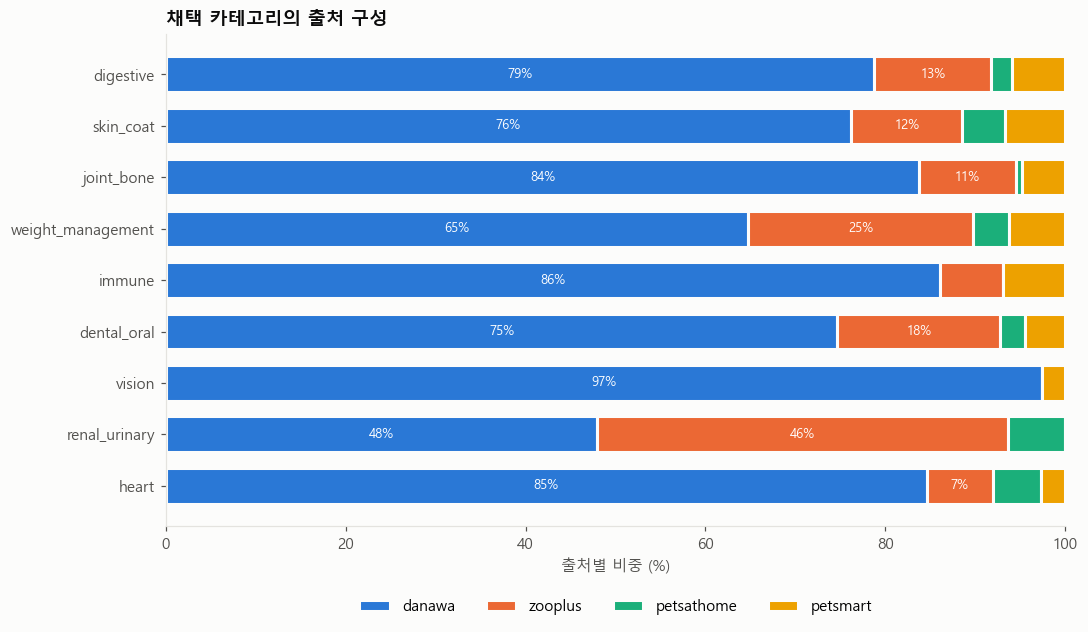

In [13]:
share = by_source.loc[adopted[::-1]].div(by_source.loc[adopted[::-1]].sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 0.45 * len(share) + 1.8))
left = np.zeros(len(share))
for s in SOURCE_ORDER:
    ax.barh(share.index, share[s], left=left, height=0.7, color=SOURCE_COLOR[s], label=s,
            edgecolor=SURFACE, linewidth=2)
    for yi, (v, l) in enumerate(zip(share[s], left)):
        if v >= 7:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left += share[s].to_numpy()
ax.set_xlim(0, 100)
ax.set_xlabel("출처별 비중 (%)")
ax.set_title("채택 카테고리의 출처 구성")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_source_share.png", dpi=150)
plt.show()

### 3-4. 원문 라벨 → 채택 카테고리 매핑 (`기능카테고리사전.csv`)

In [14]:
mapping_table = (dictionary[dictionary["학습채택"] == "adopted"]
                 .groupby(["카테고리", "출처"])["원문라벨"].agg(lambda s: ", ".join(sorted(s)))
                 .unstack("출처").reindex(index=adopted, columns=SOURCE_ORDER).fillna("—"))
mapping_table.insert(0, "이름", mapping_table.index.map(category_name))
mapping_table

출처,이름,danawa,zooplus,petsathome,petsmart
카테고리,,,,,
digestive,소화·장 건강,소화·장건강,Stomach & digestive care,소화기,"Digestive Care, Gastrointestinal, Sensitive St..."
skin_coat,피부·모질,피부·모질개선,"Hair-, fur- & skin care",피부,"Sensitive Skin, Shiny Coat, Skin & Coat"
joint_bone,관절·뼈,관절·뼈건강,Joints & bone care,관절,"Bone Development, Hip & Joint, Mobility"
weight_management,체중 관리,체중관리,Weight management,체중,Weight Control
immune,면역,면역력강화,Immune system,—,Immune Support
dental_oral,치아·구강,치석예방·제거,Dental care & hygiene,치아,Dental
vision,눈 건강,눈건강·눈물,—,—,"Eye Care, Eye Health, Vision"
renal_urinary,신장·요로,신장·요로건강,"Renal care, Urinary care","비뇨기, 신장",—
heart,심장,심장건강,Heart care,심장,"Cardiac, Heart Health"


### 3-5. 상품별 카테고리 채택 현황

Gold 상품을 카테고리 상태에 따라 세 그룹으로 나눈다.

| 그룹 | 조건 |
| --- | --- |
| 채택 | `학습카테고리`가 있음 (채택 카테고리가 1개 이상) |
| 미채택 | `기능카테고리`는 있지만 모두 보류 카테고리 (`학습카테고리` 없음) |
| 카테고리 없음 | `기능카테고리`가 없음 (건강기능이 아닌 라벨만 있음) |

In [15]:
GROUPS = ["채택", "미채택 (보류 카테고리만)", "카테고리 없음 (비기능 라벨만)"]
df["카테고리_상태"] = pd.Categorical(
    np.select([df["학습카테고리"].notna(), df["기능카테고리"].notna()], GROUPS[:2], default=GROUPS[2]),
    categories=GROUPS)

status = pd.crosstab(df["카테고리_상태"], df["출처"], margins=True, margins_name="합계")
status["비율_%"] = (status["합계"] / len(df) * 100).round(1)
status

출처,danawa,zooplus,petsathome,petsmart,합계,비율_%
카테고리_상태,,,,,,
채택,1796,996,373,188,3353,71.8
미채택 (보류 카테고리만),17,41,13,2,73,1.6
카테고리 없음 (비기능 라벨만),17,653,284,289,1243,26.6
합계,1830,1690,670,479,4669,100.0


In [16]:
# 미채택 그룹의 카테고리, 카테고리 없음 그룹의 원문 라벨
held = df.loc[df["카테고리_상태"] == GROUPS[1], "기능카테고리"].str.split("|").explode().value_counts()
no_cat = df.loc[df["카테고리_상태"] == GROUPS[2], "기능_원문"].str.split("|").explode().value_counts()
display(held.rename("상품 수").rename_axis("미채택 그룹의 보류 카테고리").to_frame())
no_cat.head(10).rename("상품 수").rename_axis("카테고리 없음 그룹의 원문 라벨 (상위 10)").to_frame()

,상품 수
미채택 그룹의 보류 카테고리,
liver,24
stress,23
diabetes,15
recovery,4
brain_health,4
cancer_support,2
pain_relief,1


,상품 수
카테고리 없음 그룹의 원문 라벨 (상위 10),
Sensitive,412
저알러지,284
General Health,283
Hypoallergenic,184
Performance,76
Senility,20
Sterilised,17
임신·수유,13
Appetite support,10


### 3-6. 관찰

- 기준(95% 신뢰수준, ±10%p, 5-fold 교차검증)을 적용하면 **9개 카테고리**가 채택되고, 이들이 건강기능 라벨의 97.1%를 차지한다. 10위 stress(71건)는 오차 ±0.116으로 기준을 넘는다.
- 같은 상품 수라도 8:2 단일 분할로 평가하면 오차가 약 2.2배($\sqrt{5}$배) 커서, 4개만 기준을 충족한다.
- **모든 채택 카테고리에서 다나와 비중이 가장 크다** (48~97%). 특히 vision은 97%가 다나와라서 출처 편향의 위험이 가장 크다.
- 신장(renal)과 요로(urinary)를 따로 두면 다나와 `신장·요로건강` 82건이 두 카테고리에 똑같이 들어가 구분할 수 없다. 그래서 `renal_urinary`(171건) 하나로 합쳤다. 다나와 비중은 48%로 채택 카테고리 중 가장 낮다.
- 교차검증의 오차는 회차 간 학습 데이터가 겹쳐 실제보다 약간 낙관적인 근사값이다.

## 4. 사료형태와 성분 결측

성분을 분석하기 전에 두 가지를 확인한다.
1. **건식과 습식의 비율**: 습식은 수분이 약 80%라 현물 기준 성분값이 건식보다 훨씬 낮게 나온다. 두 형태가 얼마나 섞여 있는지에 따라 분석 방식(형태별 분리 또는 건물기준 환산)이 달라진다.
2. **성분별 결측**: 어떤 성분을 분석에 쓸 수 있는지, 결측이 출처나 형태에 몰려 있는지 본다.

### 4-1. 사료형태 대분류

`사료형태`는 복수값(예: `동결건조|건식`)이므로 통합 데이터의 `형태대분류` 속성에 아래 규칙으로 하나의 대분류를 넣었다 (`build_dataset.py`의 `form_group`). 규칙은 그룹별 수분 중앙값으로 확인했다.

| 대분류 | 규칙 (위에서부터 적용) | 수분 중앙값 |
| --- | --- | --- |
| 습식 | 습식·화식·냉동 포함 | 72~95% |
| 반건조 | 반건조만 (건식과 함께면 건식) | 25% |
| 건식 | 건식·동결건조·에어드라이·탈수건조 포함 | 5~18% |
| 습식 | 토퍼만 | 86% |
| 미상 | 사료형태 없음 | |

In [17]:
FORM_ORDER = ["건식", "습식", "반건조", "미상"]
FORM_COLOR = dict(zip(FORM_ORDER, ["#6250d6", "#008300", "#e87ba4", "#c3c2b7"]))

df["형태대분류"] = pd.Categorical(df["형태대분류"], categories=FORM_ORDER)
check = df.groupby("형태대분류", observed=True).agg(상품수=("상품ID", "size"), 수분_중앙값=("수분_실측_pct", "median"))
check["비율_%"] = (check["상품수"] / len(df) * 100).round(1)
check

,상품수,수분_중앙값,비율_%
형태대분류,,,
건식,3387,10.0,72.5
습식,1033,78.0,22.1
반건조,190,25.0,4.1
미상,59,10.0,1.3


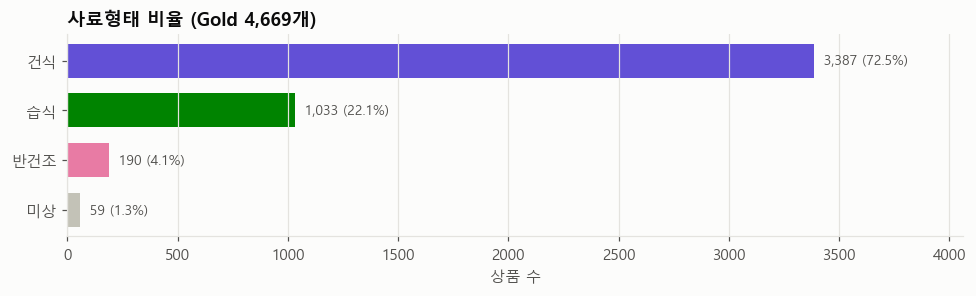

In [18]:
# 그래프: 전체 사료형태 비율
vc = df["형태대분류"].value_counts().reindex(FORM_ORDER).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(vc.index.astype(str), vc.values, color=[FORM_COLOR[f] for f in vc.index], height=0.68)
for y, v in enumerate(vc.values):
    ax.text(v, y, f"  {v:,} ({v / len(df) * 100:.1f}%)", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, vc.max() * 1.2)
ax.set_xlabel("상품 수")
ax.set_title(f"사료형태 비율 (Gold {len(df):,}개)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "food_type_share.png", dpi=150)
plt.show()

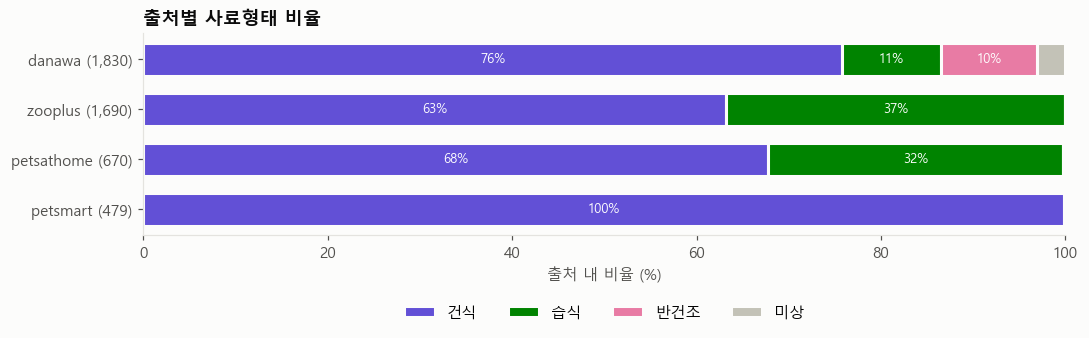

In [19]:
# 그래프: 출처별 사료형태 비율
form_src = pd.crosstab(df["출처"], df["형태대분류"], normalize="index").reindex(columns=FORM_ORDER) * 100
form_src = form_src.loc[SOURCE_ORDER[::-1]]
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(form_src))
for f in FORM_ORDER:
    ax.barh(form_src.index.astype(str), form_src[f], left=left, height=0.66, color=FORM_COLOR[f], label=f,
            edgecolor=SURFACE, linewidth=2)
    for yi, (v, l) in enumerate(zip(form_src[f], left)):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color=INK if f == "미상" else "white")
    left += form_src[f].to_numpy()
n_src = df["출처"].value_counts()
ax.set_yticks(range(len(form_src)), [f"{s} ({n_src[s]:,})" for s in form_src.index])
ax.set_xlim(0, 100)
ax.set_xlabel("출처 내 비율 (%)")
ax.set_title("출처별 사료형태 비율")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "food_type_by_source.png", dpi=150)
plt.show()

### 4-2. 성분 결측

현물 기준 주요 성분 8종, 열량, 미량성분 7종의 결측률을 본다. 수분은 **추정으로 채우기 전**(실측값만) 기준이다. 건물기준 성분은 `수분_pct`가 있어야 계산되므로 결측 패턴이 수분과 같아 생략했다.

In [20]:
from matplotlib.colors import LinearSegmentedColormap

NUTRIENTS = ["조단백_pct", "조지방_pct", "조섬유_pct", "조회분_pct", "수분_pct", "칼슘_pct", "인_pct", "나트륨_pct",
             "열량_kcal_kg", "오메가3_pct", "오메가6_pct", "EPA_DHA합_pct", "타우린_pct", "글루코사민_mg_kg",
             "L카르니틴_mg_kg", "칼륨_pct", "마그네슘_pct"]
nut = df.assign(수분_pct=df["수분_실측_pct"])  # 4-2절은 추정 전 상태를 본다: 수분은 실측값만
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

missing = (nut[NUTRIENTS].isna().mean() * 100).round(1).sort_values()
print(f"주요 5성분(단백·지방·섬유·회분·수분)이 모두 있는 상품: "
      f"{nut[NUTRIENTS[:5]].notna().all(axis=1).sum():,}개 ({nut[NUTRIENTS[:5]].notna().all(axis=1).mean() * 100:.1f}%)")
missing.rename("결측률_%").to_frame().T

주요 5성분(단백·지방·섬유·회분·수분)이 모두 있는 상품: 2,042개 (43.7%)


,조단백_pct,조지방_pct,조섬유_pct,조회분_pct,수분_pct,칼슘_pct,인_pct,열량_kcal_kg,오메가3_pct,오메가6_pct,나트륨_pct,칼륨_pct,마그네슘_pct,글루코사민_mg_kg,타우린_pct,EPA_DHA합_pct,L카르니틴_mg_kg
결측률_%,4.2,4.3,20.8,30.6,46.6,49.8,50.4,77.7,82.2,83.6,88.0,90.9,92.8,94.9,95.5,99.0,99.0


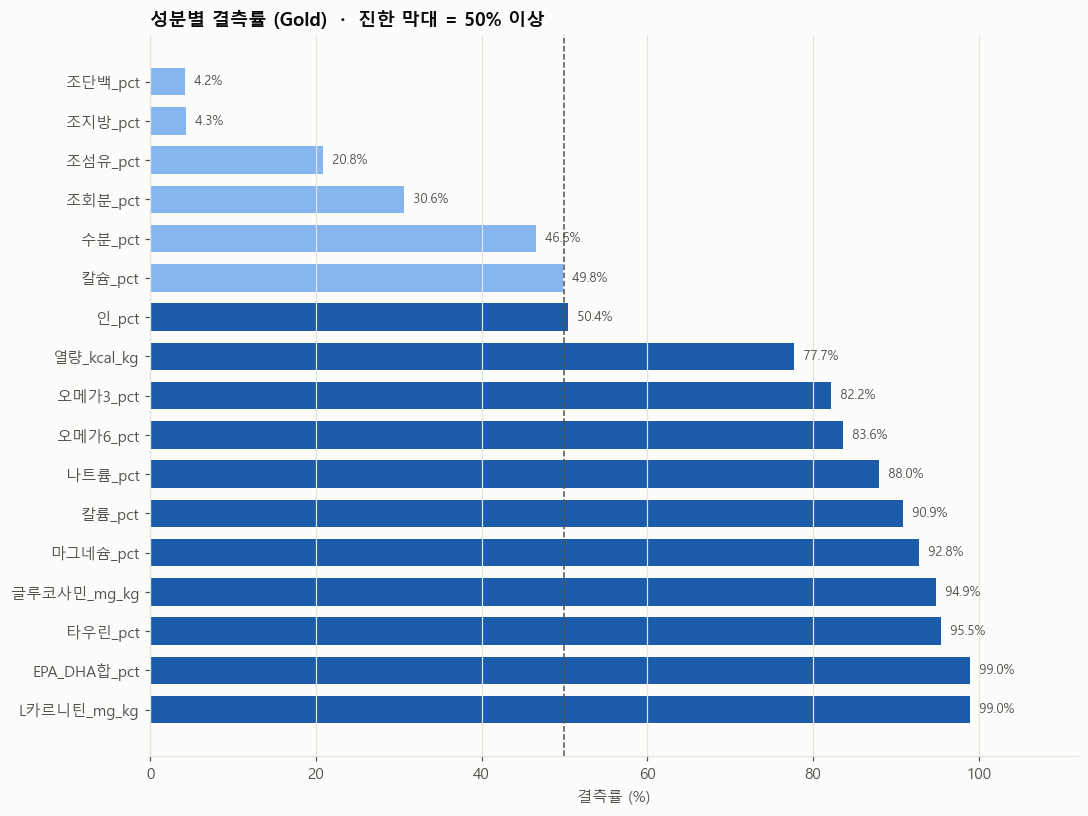

In [21]:
# 그래프: 성분별 결측률
m = missing.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.36 * len(m) + 1.4))
ax.barh(m.index, m.values, height=0.7, color=["#1c5cab" if v >= 50 else "#86b6ef" for v in m.values])
for y, v in enumerate(m.values):
    ax.text(v, y, f"  {v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.axvline(50, color=INK2, lw=1, ls="--")
ax.set_xlim(0, 112)
ax.set_xlabel("결측률 (%)")
ax.set_title("성분별 결측률 (Gold)  ·  진한 막대 = 50% 이상")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "nutrient_missing_rate.png", dpi=150)
plt.show()

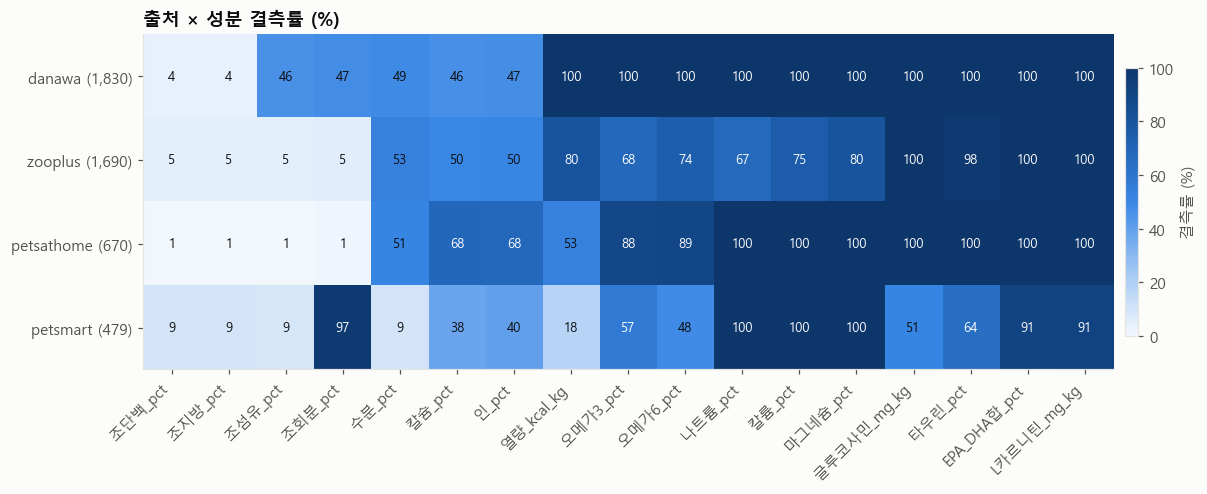

In [22]:
# 그래프: 출처 × 성분 결측률 (%)
rate = (nut[NUTRIENTS].isna().groupby(df["출처"], observed=True).mean() * 100).reindex(SOURCE_ORDER).dropna(how="all")
rate = rate[missing.index]  # 열 순서: 전체 결측률이 낮은 성분부터
counts = df["출처"].value_counts()
fig, ax = plt.subplots(figsize=(12, 0.55 * len(rate) + 2.4))
im = ax.imshow(rate.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(rate.shape[1]), rate.columns, rotation=45, ha="right")
ax.set_yticks(range(len(rate)), [f"{g} ({counts[g]:,})" for g in rate.index])
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v >= 55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, label="결측률 (%)")
ax.set_title("출처 × 성분 결측률 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "nutrient_missing_by_source.png", dpi=150)
plt.show()

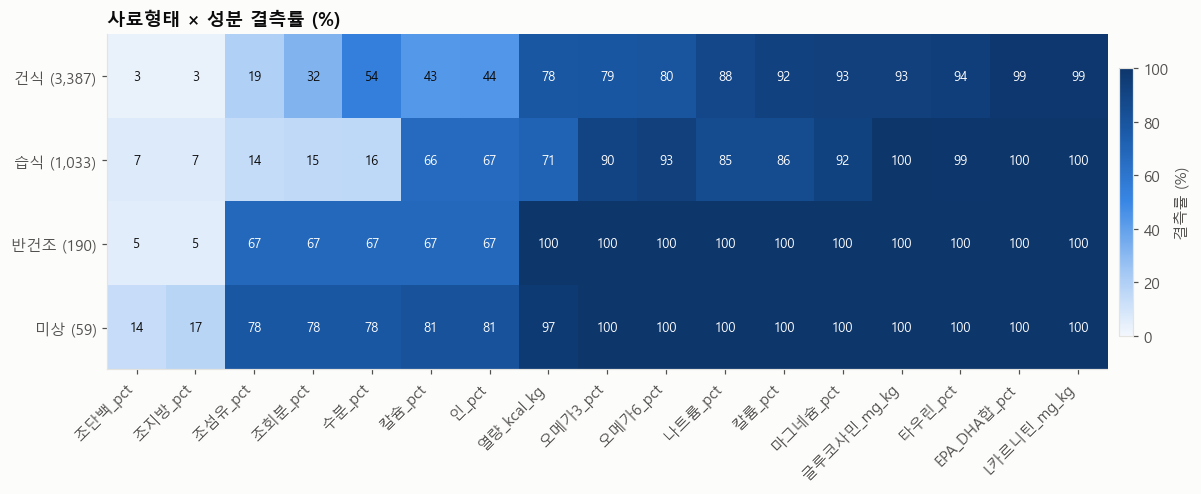

In [23]:
# 그래프: 사료형태 × 성분 결측률 (%)
rate = (nut[NUTRIENTS].isna().groupby(df["형태대분류"], observed=True).mean() * 100).reindex(FORM_ORDER).dropna(how="all")
rate = rate[missing.index]  # 열 순서: 전체 결측률이 낮은 성분부터
counts = df["형태대분류"].value_counts()
fig, ax = plt.subplots(figsize=(12, 0.55 * len(rate) + 2.4))
im = ax.imshow(rate.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(rate.shape[1]), rate.columns, rotation=45, ha="right")
ax.set_yticks(range(len(rate)), [f"{g} ({counts[g]:,})" for g in rate.index])
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v >= 55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, label="결측률 (%)")
ax.set_title("사료형태 × 성분 결측률 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "nutrient_missing_by_food_type.png", dpi=150)
plt.show()

### 4-3. 건물기준 성분 결측 (실측 수분 기준, 추정 전)

통합 데이터는 수분이 없는 건식의 건물기준값을 추정 수분으로 채운다(`수분추정여부=True`, 4-5절). 이 절은 **추정하기 전**, 실측 수분만으로 계산할 수 있는 건물기준값의 결측을 본다.

건물기준 값은 `현물값 ÷ (1 − 수분/100)`으로 계산하므로, 값이 비는 원인은 다음 셋 중 하나다.

| 원인 | 의미 |
| --- | --- |
| 수분 없음 | 현물값은 있지만 수분이 없어 환산할 수 없음 |
| 현물값 없음 | 수분은 있지만 해당 성분의 현물값이 없음 |
| 둘 다 없음 | 현물값과 수분이 모두 없음 |

다나와 `영양_DM표기` 상품 10개는 현물값 없이 원본이 건물기준 값만 제공해서, 현물값이 없어도 건물기준 값이 있을 수 있다.

In [24]:
DM_PAIRS = [(f"건물기준_{n}_pct", f"{n}_pct") for n in ["조단백", "조지방", "조섬유", "조회분", "칼슘", "인", "나트륨"]]
DM_COLS = [dm for dm, _ in DM_PAIRS]
REASONS = ["값 있음", "수분 없음", "현물값 없음", "둘 다 없음"]
REASON_COLOR = dict(zip(REASONS, ["#2a78d6", "#eda100", "#e87ba4", "#c3c2b7"]))

estimated = df["수분추정여부"] == True
dm_measured = df[DM_COLS].mask(estimated, axis=0)  # 추정 수분으로 채운 값을 뺀 실측 기준 건물기준값

has_moist = df["수분_실측_pct"].notna()
reason = {}
for dm, raw in DM_PAIRS:
    has_dm, has_raw = dm_measured[dm].notna(), df[raw].notna()
    reason[dm.removeprefix("건물기준_").removesuffix("_pct")] = pd.Series({
        "값 있음": has_dm.sum(),
        "수분 없음": (~has_dm & has_raw & ~has_moist).sum(),
        "현물값 없음": (~has_dm & ~has_raw & has_moist).sum(),
        "둘 다 없음": (~has_dm & ~has_raw & ~has_moist).sum(),
    })
reason = pd.DataFrame(reason).T
assert (reason.sum(axis=1) == len(df)).all()
dm_missing = (dm_measured.isna().mean() * 100).round(1)
print("건물기준 성분 결측률 (실측 수분 기준, %):", dm_missing.to_dict())
(reason / len(df) * 100).round(1)

건물기준 성분 결측률 (실측 수분 기준, %): {'건물기준_조단백_pct': 46.5, '건물기준_조지방_pct': 46.6, '건물기준_조섬유_pct': 46.9, '건물기준_조회분_pct': 56.1, '건물기준_칼슘_pct': 64.5, '건물기준_인_pct': 64.9, '건물기준_나트륨_pct': 95.3}


,값 있음,수분 없음,현물값 없음,둘 다 없음
조단백,53.5,42.5,0.0,4.0
조지방,53.4,42.5,0.1,4.0
조섬유,53.1,26.1,0.3,20.5
조회분,43.9,25.5,9.5,21.1
칼슘,35.5,14.7,17.9,31.8
인,35.1,14.5,18.3,32.1
나트륨,4.7,7.3,48.7,39.3


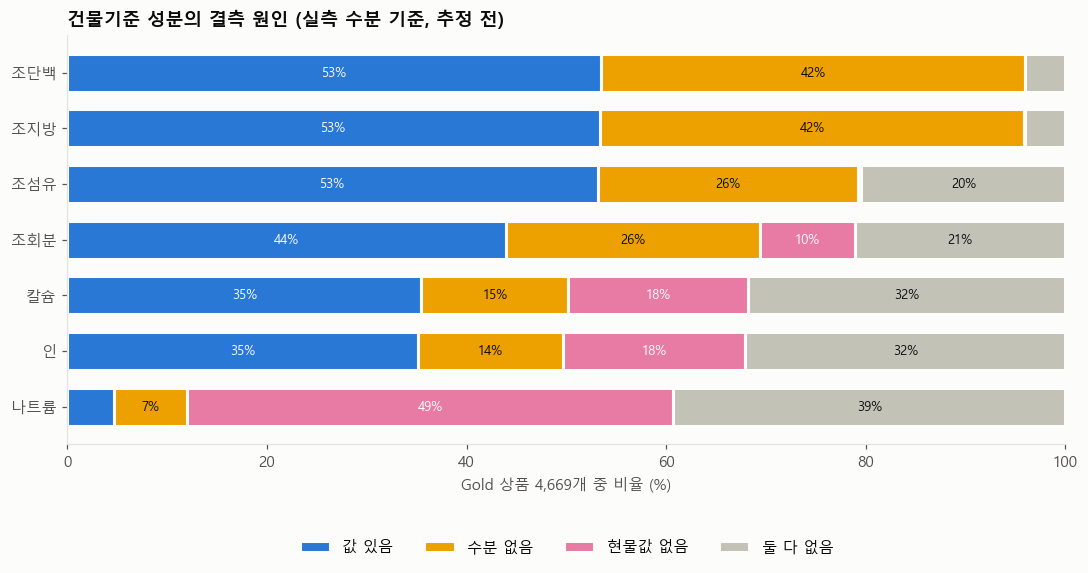

In [25]:
# 그래프: 건물기준 성분별 결측 원인
share = (reason / len(df) * 100).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.5 * len(share) + 1.9))
left = np.zeros(len(share))
for r in REASONS:
    ax.barh(share.index, share[r], left=left, height=0.68, color=REASON_COLOR[r], label=r,
            edgecolor=SURFACE, linewidth=2)
    for yi, (v, l) in enumerate(zip(share[r], left)):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color=INK if r in ("수분 없음", "둘 다 없음") else "white")
    left += share[r].to_numpy()
ax.set_xlim(0, 100)
ax.set_xlabel(f"Gold 상품 {len(df):,}개 중 비율 (%)")
ax.set_title("건물기준 성분의 결측 원인 (실측 수분 기준, 추정 전)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "dm_missing_reason.png", dpi=150)
plt.show()

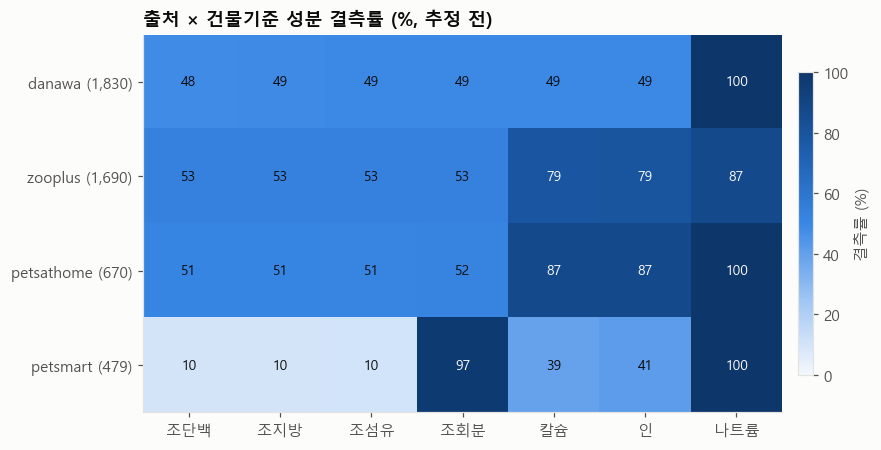

In [26]:
# 그래프: 출처 × 건물기준 성분 결측률 (%, 추정 전)
rate = (dm_measured.isna().groupby(df["출처"], observed=True).mean() * 100).reindex(SOURCE_ORDER).dropna(how="all")
rate.columns = [c.removeprefix("건물기준_").removesuffix("_pct") for c in rate.columns]
counts = df["출처"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(rate) + 2))
im = ax.imshow(rate.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(rate.shape[1]), rate.columns)
ax.set_yticks(range(len(rate)), [f"{g} ({counts[g]:,})" for g in rate.index])
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v >= 55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label="결측률 (%)")
ax.set_title("출처 × 건물기준 성분 결측률 (%, 추정 전)")
fig.tight_layout()
fig.savefig(FIG_DIR / "dm_missing_by_source.png", dpi=150)
plt.show()

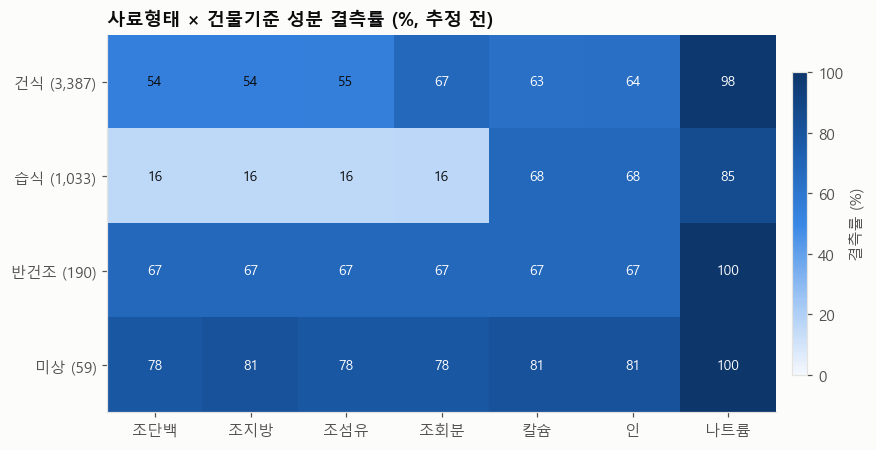

In [27]:
# 그래프: 사료형태 × 건물기준 성분 결측률 (%, 추정 전)
rate = (dm_measured.isna().groupby(df["형태대분류"], observed=True).mean() * 100).reindex(FORM_ORDER).dropna(how="all")
rate.columns = [c.removeprefix("건물기준_").removesuffix("_pct") for c in rate.columns]
counts = df["형태대분류"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(rate) + 2))
im = ax.imshow(rate.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(rate.shape[1]), rate.columns)
ax.set_yticks(range(len(rate)), [f"{g} ({counts[g]:,})" for g in rate.index])
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v >= 55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label="결측률 (%)")
ax.set_title("사료형태 × 건물기준 성분 결측률 (%, 추정 전)")
fig.tight_layout()
fig.savefig(FIG_DIR / "dm_missing_by_food_type.png", dpi=150)
plt.show()

### 4-4. 건식 사료의 건강기능 카테고리별 수분 함량

건식(형태대분류 = 건식) 중 중복이 아닌 상품을 `학습카테고리` 기준으로 나눠 수분 분포를 본다. 한 상품이 여러 카테고리에 속하면 각 카테고리에 모두 들어간다.
맨 위 회색 상자는 건식 전체(카테고리 무관)의 분포로, 비교 기준이다. 오른쪽 숫자는 `수분 있음 / 카테고리 상품 수`이다.

In [28]:
dry = df[(df["형태대분류"] == "건식") & (df["중복여부"] != True)]
dry_cat = (dry.dropna(subset=["학습카테고리"])
           .assign(카테고리=lambda t: t["학습카테고리"].str.split("|")).explode("카테고리"))

moist = dry_cat.groupby("카테고리")["수분_실측_pct"]
moist_table = pd.DataFrame({"상품수": moist.size(), "수분있음": moist.count()}).reindex(adopted)
moist_table["수분있음_%"] = (moist_table["수분있음"] / moist_table["상품수"] * 100).round(0)
moist_table = moist_table.join(moist.describe()[["25%", "50%", "75%", "mean"]].round(1))
moist_table.loc["(건식 전체)"] = [len(dry), dry["수분_실측_pct"].count(), round(dry["수분_실측_pct"].notna().mean() * 100),
                                 *dry["수분_실측_pct"].describe()[["25%", "50%", "75%", "mean"]].round(1)]
moist_table

,상품수,수분있음,수분있음_%,25%,50%,75%,mean
카테고리,,,,,,,
digestive,1146.0,587.0,51.0,10.0,10.5,12.0,10.8
skin_coat,951.0,473.0,50.0,10.0,10.5,12.0,10.9
joint_bone,645.0,347.0,54.0,10.0,11.0,12.0,11.4
weight_management,495.0,269.0,54.0,10.0,10.0,12.0,10.4
immune,325.0,170.0,52.0,10.0,10.0,12.0,10.7
dental_oral,187.0,102.0,55.0,10.1,10.5,12.0,10.8
vision,124.0,63.0,51.0,11.0,12.0,12.0,12.2
renal_urinary,105.0,35.0,33.0,10.5,10.5,11.0,10.6
heart,107.0,83.0,78.0,10.0,10.0,12.0,11.1


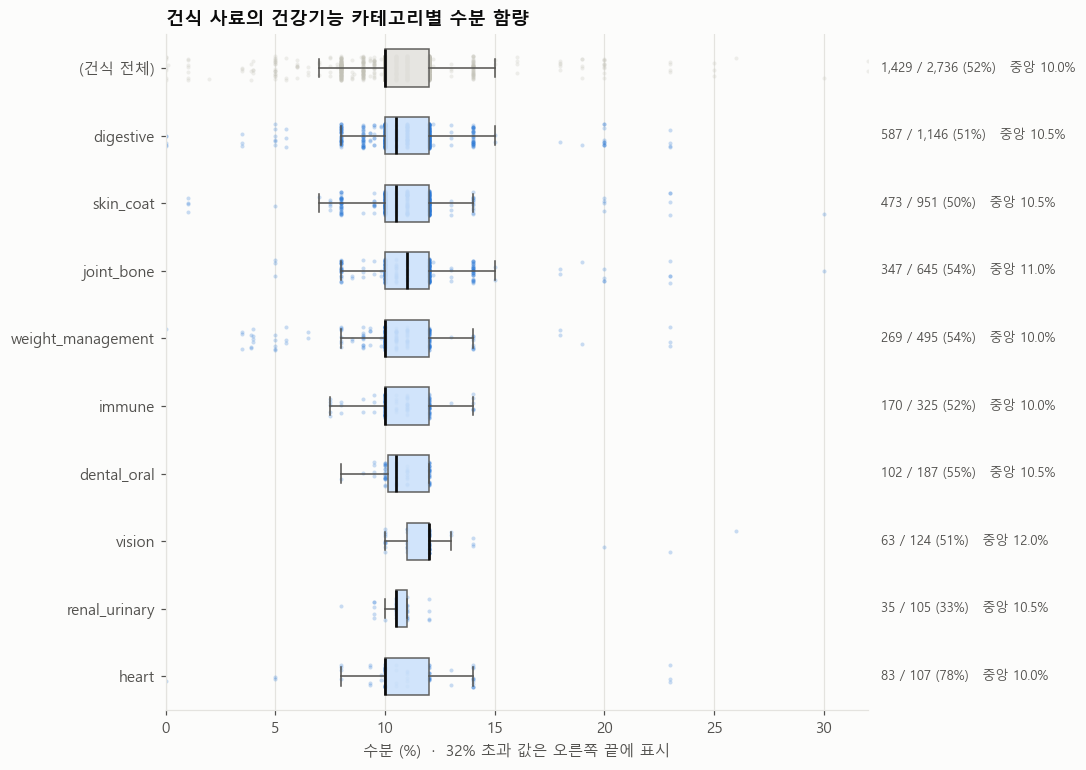

In [29]:
# 그래프: 건식 사료의 카테고리별 수분 분포
rows = ["(건식 전체)"] + adopted
data = [dry["수분_실측_pct"].dropna()] + [dry_cat.loc[dry_cat["카테고리"] == c, "수분_실측_pct"].dropna() for c in adopted]
ypos = np.arange(len(rows))[::-1]  # 위에서부터 rows 순서
X_MAX = 32

fig, ax = plt.subplots(figsize=(10, 0.55 * len(rows) + 1.6))
rng = np.random.default_rng(0)
for y, vals, name in zip(ypos, data, rows):
    color = "#c3c2b7" if name == "(건식 전체)" else ADOPT
    ax.scatter(vals.clip(upper=X_MAX), y + rng.uniform(-0.18, 0.18, len(vals)), s=7, alpha=0.25,
               color=color, linewidth=0, zorder=2)
bp = ax.boxplot(data, positions=ypos, vert=False, widths=0.55, showfliers=False, patch_artist=True,
                medianprops=dict(color=INK, lw=1.8), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                boxprops=dict(edgecolor=INK2, linewidth=1), zorder=3)
for patch, name in zip(bp["boxes"], rows):
    patch.set(facecolor="#e4e3df" if name == "(건식 전체)" else "#cde2fb", alpha=0.9)
for y, name in zip(ypos, rows):
    r = moist_table.loc[name]
    ax.text(X_MAX + 0.6, y, f"{int(r['수분있음']):,} / {int(r['상품수']):,} ({r['수분있음_%']:.0f}%)   중앙 {r['50%']:.1f}%",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(ypos, rows)
ax.set_xlim(0, X_MAX)
ax.set_xlabel(f"수분 (%)  ·  {X_MAX}% 초과 값은 오른쪽 끝에 표시")
ax.set_title("건식 사료의 건강기능 카테고리별 수분 함량")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "dry_moisture_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

### 4-5. 건식 수분 추정 적용

4-4절에서 건식의 수분은 카테고리와 관계없이 10~12%에 몰려 있었다. 그래서 통합 데이터는 **수분이 없는 건식**에 같은 하위 형태(일반 건식·동결건조·에어드라이·탈수건조)의 실측 수분 중앙값을 넣어 건물기준값을 채운다.
- 추정 수분은 `수분_pct`에도 채워져 있고, 추정한 행은 `수분추정여부=True`다. 실측만 볼 때는 노트북의 `수분_실측_pct`를 쓴다.
- 습식·반건조·미상은 추정하지 않는다.
- 규칙은 `build_dataset.py`의 `dry_matter`에 있고, 근거는 `gold_unified_schema.md` 5.5절에 있다.

In [30]:
import sys
sys.path.insert(0, "../scripts/gold_unified")
from build_dataset import dry_subtype  # 통합 스크립트와 같은 하위 형태 판정 규칙

is_dry = df["형태대분류"] == "건식"
df["건식하위형태"] = df["사료형태"].map(dry_subtype).where(is_dry)

# 추정에 쓰인 수분 = 건물기준값과 현물값에서 역산 (하위 형태마다 하나의 값)
est_rows = df[estimated]
implied = (100 * (1 - est_rows["조단백_pct"] / est_rows["건물기준_조단백_pct"])).round(1)
est_table = pd.DataFrame({"추정_행수": est_rows.groupby("건식하위형태").size(),
                          "추정_수분_%": implied.groupby(est_rows["건식하위형태"]).median(),
                          "실측_수분_중앙값_%": df[is_dry].groupby("건식하위형태")["수분_실측_pct"].median()})
print(f"수분 추정 행: {estimated.sum():,}개 (Gold 건식 {is_dry.sum():,}개 중 {estimated.sum() / is_dry.sum() * 100:.1f}%)")
est_table

수분 추정 행: 1,741개 (Gold 건식 3,387개 중 51.4%)


,추정_행수,추정_수분_%,실측_수분_중앙값_%
건식하위형태,,,
건식,1709.0,10.0,10.00
동결건조,29.0,6.0,6.00
에어드라이,3.0,14.0,14.00
탈수건조,NaN,NaN,8.25


**추정 오차 검증:** 실측 수분이 있는 건식에 같은 추정 규칙을 적용해 계산한 건물기준값과 실제 건물기준값을 비교한다. 비교 대상은 현물값을 그대로 복사하는 방법(수분 0% 가정)이다.

In [31]:
measured_dry = df[is_dry & df["수분_실측_pct"].notna() & (df["수분_실측_pct"] < 100)]
# Gold에 추정 행이 없는 하위 형태(탈수건조)는 같은 규칙의 값인 실측 중앙값을 쓴다
assumed = measured_dry["건식하위형태"].map(est_table["추정_수분_%"].fillna(est_table["실측_수분_중앙값_%"]))
rows = []
for n in ["조단백", "조지방", "조섬유", "조회분"]:
    actual = measured_dry[f"건물기준_{n}_pct"]
    est_err = (measured_dry[f"{n}_pct"] / (1 - assumed / 100) - actual).abs()
    copy_err = (measured_dry[f"{n}_pct"] - actual).abs()
    rows.append({"성분": n, "검증_상품수": est_err.notna().sum(),
                 "추정_오차_중앙값_%p": est_err.median(), "추정_오차_95%_%p": est_err.quantile(0.95),
                 "복사_오차_중앙값_%p": copy_err.median(), "복사_오차_95%_%p": copy_err.quantile(0.95)})
pd.DataFrame(rows).set_index("성분").round(2)

,검증_상품수,추정_오차_중앙값_%p,추정_오차_95%_%p,복사_오차_중앙값_%p,복사_오차_95%_%p
성분,,,,,
조단백,1541,0.31,1.92,2.89,4.92
조지방,1538,0.13,0.82,1.56,2.73
조섬유,1536,0.04,0.26,0.49,1.09
조회분,1111,0.11,0.67,0.89,1.63


**수분 결측: 채우기 전과 채운 후.** 사료형태별로 수분이 실측·추정·결측 중 어디에 해당하는지 비율로 본다. 두 그래프는 같은 눈금(출처 내 100%)이다.

In [32]:
MOIST_STATES = ["실측", "중앙값으로 채움", "결측"]
MOIST_COLOR = dict(zip(MOIST_STATES, ["#2a78d6", "#eda100", "#c3c2b7"]))
before_state = np.where(df["수분_실측_pct"].notna(), "실측", "결측")
after_state = np.select([df["수분_실측_pct"].notna(), df["수분추정여부"] == True], MOIST_STATES[:2], default="결측")


def plot_moisture_state(state, title, fname):
    tab = pd.crosstab(df["형태대분류"], pd.Categorical(state, categories=MOIST_STATES), dropna=False)
    tab = tab.reindex(index=FORM_ORDER[::-1], columns=MOIST_STATES, fill_value=0)
    share = tab.div(tab.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, 3.4))
    left = np.zeros(len(share))
    for s in MOIST_STATES:
        ax.barh(share.index.astype(str), share[s], left=left, height=0.66, color=MOIST_COLOR[s], label=s,
                edgecolor=SURFACE, linewidth=2)
        for yi, (v, n, l) in enumerate(zip(share[s], tab[s], left)):
            if v >= 7:
                ax.text(l + v / 2, yi, f"{v:.0f}% ({n:,})", ha="center", va="center", fontsize=8.5,
                        color="white" if s == "실측" else INK)
        left += share[s].to_numpy()
    ax.set_yticks(range(len(share)), [f"{f} ({tab.loc[f].sum():,})" for f in share.index])
    ax.set_xlim(0, 100)
    ax.set_xlabel("사료형태 내 비율 (%)")
    ax.set_title(title)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
    ax.grid(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150)
    plt.show()
    return tab

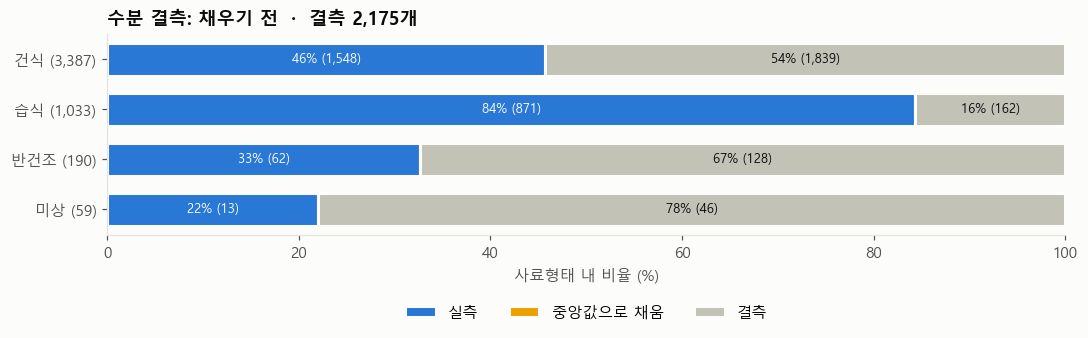

col_0,실측,중앙값으로 채움,결측
형태대분류,,,
미상,13,0,46
반건조,62,0,128
습식,871,0,162
건식,1548,0,1839


In [33]:
# 그래프 1: 수분 결측 - 채우기 전
plot_moisture_state(before_state, f"수분 결측: 채우기 전  ·  결측 {(before_state == '결측').sum():,}개",
                    "moisture_missing_before.png")

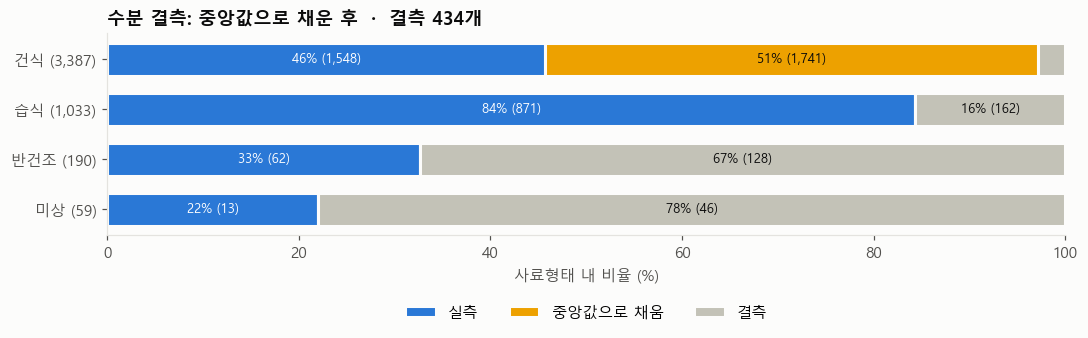

col_0,실측,중앙값으로 채움,결측
형태대분류,,,
미상,13,0,46
반건조,62,0,128
습식,871,0,162
건식,1548,1741,98


In [34]:
# 그래프 2: 수분 결측 - 채운 후 (건식만 하위 형태별 중앙값으로 채움)
plot_moisture_state(after_state, f"수분 결측: 중앙값으로 채운 후  ·  결측 {(after_state == '결측').sum():,}개",
                    "moisture_missing_after.png")

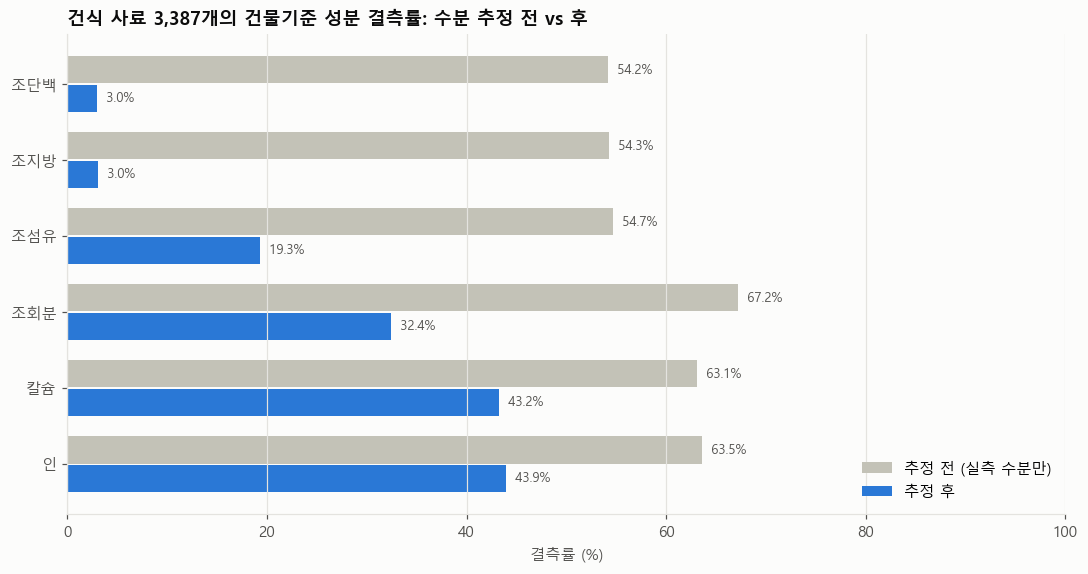

In [35]:
# 그래프: 건식 사료의 건물기준 결측률, 추정 전 vs 후
DM_SHOW = ["조단백", "조지방", "조섬유", "조회분", "칼슘", "인"]
dry_df = df[is_dry]
before = pd.Series({n: dm_measured.loc[is_dry, f"건물기준_{n}_pct"].isna().mean() * 100 for n in DM_SHOW})
after = pd.Series({n: dry_df[f"건물기준_{n}_pct"].isna().mean() * 100 for n in DM_SHOW})

y = np.arange(len(DM_SHOW))[::-1]
fig, ax = plt.subplots(figsize=(10, 0.62 * len(DM_SHOW) + 1.6))
ax.barh(y + 0.19, before.values, height=0.36, color="#c3c2b7", label="추정 전 (실측 수분만)")
ax.barh(y - 0.19, after.values, height=0.36, color=ADOPT, label="추정 후")
for yi, b, a in zip(y, before.values, after.values):
    ax.text(b, yi + 0.19, f"  {b:.1f}%", va="center", fontsize=8.5, color=INK2)
    ax.text(a, yi - 0.19, f"  {a:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, DM_SHOW)
ax.set_xlim(0, 100)
ax.set_xlabel("결측률 (%)")
ax.set_title(f"건식 사료 {len(dry_df):,}개의 건물기준 성분 결측률: 수분 추정 전 vs 후")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "dm_missing_dry_before_after.png", dpi=150)
plt.show()

**건식과 습식의 건물기준 성분 비교:** 수분을 뺀 고형분 기준이라 건식과 습식을 같은 눈금에서 비교할 수 있다. 중복 상품은 제외했다.
건식은 실측 수분만 쓴 경우와 추정 수분을 포함한 경우를 함께 그려, 추정이 분포를 바꾸지 않는지 확인한다.

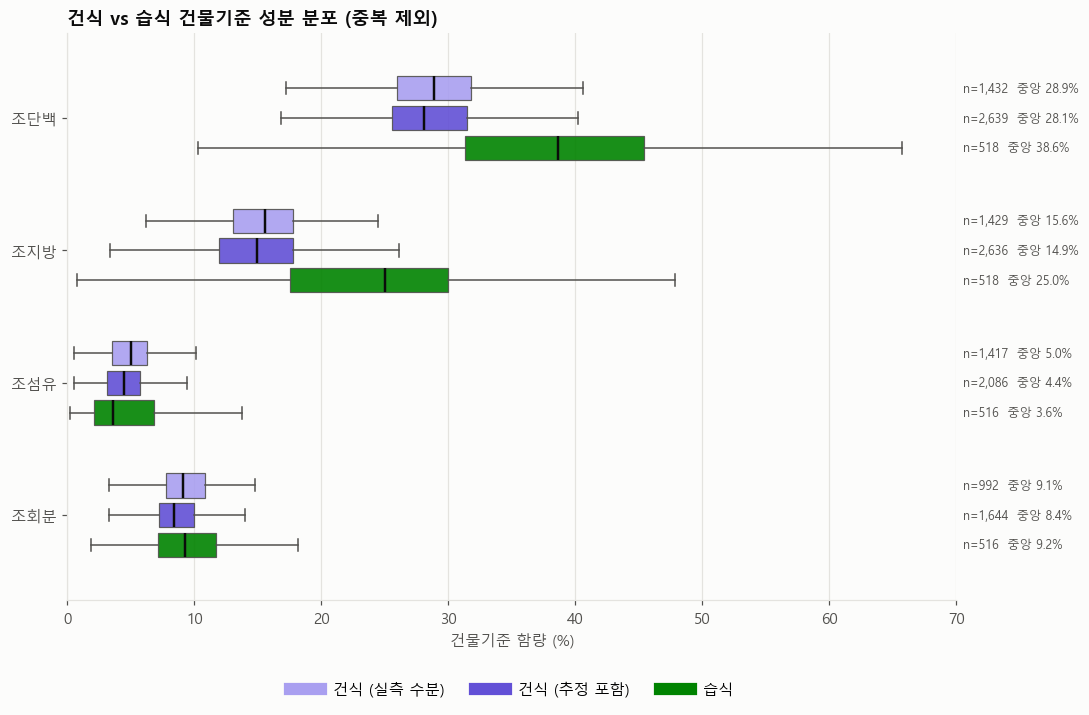

In [36]:
# 그래프: 건식 vs 습식 건물기준 성분 분포
COMPARE = ["조단백", "조지방", "조섬유", "조회분"]
base = df[df["중복여부"] != True]
SERIES = [("건식 (실측 수분)", (base["형태대분류"] == "건식") & (base["수분추정여부"] != True), "#a99ff0"),
          ("건식 (추정 포함)", base["형태대분류"] == "건식", "#6250d6"),
          ("습식", base["형태대분류"] == "습식", "#008300")]
X_MAX = 70
offsets = [0.27, 0, -0.27]

fig, ax = plt.subplots(figsize=(10, 1.25 * len(COMPARE) + 1.6))
centers = np.arange(len(COMPARE))[::-1] * 1.2
for (label, mask, color), off in zip(SERIES, offsets):
    data = [base.loc[mask, f"건물기준_{n}_pct"].dropna() for n in COMPARE]
    bp = ax.boxplot(data, positions=centers + off, vert=False, widths=0.22, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.6), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                    boxprops=dict(edgecolor=INK2, linewidth=0.8))
    for patch in bp["boxes"]:
        patch.set(facecolor=color, alpha=0.9)
    for c, vals in zip(centers, data):
        ax.text(X_MAX + 0.5, c + off, f"n={len(vals):,}  중앙 {vals.median():.1f}%", va="center", fontsize=8, color=INK2)
    ax.plot([], [], color=color, lw=8, label=label)
ax.set_yticks(centers, COMPARE)
ax.set_xlim(0, X_MAX)
ax.set_xlabel("건물기준 함량 (%)")
ax.set_title("건식 vs 습식 건물기준 성분 분포 (중복 제외)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "dm_dry_vs_wet.png", dpi=150, bbox_inches="tight")
plt.show()

### 4-6. 관찰

**사료형태**
- 건식 3,387개(72.5%), 습식 1,033개(22.1%), 반건조 190개(4.1%), 미상 59개(1.3%)로 **건식이 대부분**이다.
- 출처별 차이가 크다. PetSmart는 건식 카테고리만 수집해 100% 건식이고, Zooplus(37%)와 Pets at Home(32%)은 습식 비중이 높다. 반건조는 거의 다나와(10%)에서 나온다.
- 따라서 건식과 습식을 섞어 현물 기준으로 비교하면 형태 차이가 출처 차이와 겹쳐 나타난다. 성분 비교는 **건식만 따로** 하거나 **건물기준**으로 환산해서 한다.

**성분 결측**
- **조단백·조지방은 결측 4%**로 모든 출처·형태에서 분석할 수 있다. 조섬유(21%)와 조회분(31%)이 그다음이다.
- **수분·칼슘·인은 약 50% 결측**이다. 특히 **건식의 수분 결측이 54%**로, 습식(16%)보다 훨씬 높다. 건식 라벨에 수분을 표기하지 않은 경우가 많기 때문이다. 건물기준 환산이 수분에 의존하므로, 건식은 건물기준으로 비교할 수 있는 상품이 절반 정도로 줄어든다.
- 결측이 출처에 몰려 있다.
  - PetSmart는 조회분이 97% 결측이다.
  - 다나와는 열량과 미량성분이 100% 결측이다.
  - 나트륨·칼륨·마그네슘은 사실상 Zooplus에만 있다.
  - 글루코사민·타우린·EPA·DHA·L-카르니틴은 사실상 PetSmart에만 있다.
- 결측률 75%가 넘는 열량과 미량성분 9종은 출처 하나에 몰려 있어서, 출처 간 비교나 모델 입력으로 쓰기 어렵다. 성분 분석의 중심은 **조단백·조지방·조섬유·조회분**(+ 수분이 있는 상품의 건물기준값)으로 잡는다.
- 반건조와 미상 형태는 조섬유 이하 성분이 67~81% 결측이라 성분 비교에서 비중이 작다.

**건물기준 성분 결측**
- 건물기준 조단백·조지방·조섬유는 약 47% 결측이고, 조회분 56%, 칼슘·인 65%, 나트륨 95% 결측이다.
- **조단백·조지방의 결측은 거의 전부(42.5%p) 수분이 없어서 생긴다.** 현물값은 96% 있으므로, 수분만 있으면 건물기준으로 비교할 수 있는 상품이 크게 늘어난다.
- 칼슘·인·나트륨은 현물값 자체가 없는 경우가 더 많아서, 수분을 보충해도 크게 늘지 않는다.
- **출처별:** PetSmart는 수분이 91% 있어 조단백·조지방·조섬유의 건물기준 결측이 10%로 가장 낮다. 다만 조회분은 현물값이 없어 97% 결측이다. 나머지 세 출처는 48~53% 결측으로 비슷하다.
- **사료형태별:** 습식은 수분 표기가 많아 결측이 16%로 낮다. 반면 **건식은 54~55% 결측**이다. 즉 성분 분석의 중심인 건식에서 건물기준으로 비교할 수 있는 상품은 절반 정도다.
- 건식은 수분이 대부분 10% 안팎이라, 수분이 없는 건식은 현물값으로 비교하고 습식과 비교할 때만 건물기준을 쓰는 방식도 검토할 수 있다.

**건식 사료의 카테고리별 수분**
- 9개 카테고리 모두 **수분 중앙값이 10.0~12.0%, 사분위 범위가 대략 10~12%**로, 건식 전체(중앙 10.0%)와 거의 같다. 건강기능 카테고리에 따라 건식 사료의 수분이 달라지지 않는다.
- vision이 중앙 12.0%로 가장 높지만, 수분 값이 63개뿐이고 거의 다나와 상품이라 출처의 표기 관행일 가능성이 크다.
- 수분이 있는 비율은 대부분 50~55%다. heart는 78%로 높고, renal_urinary는 33%로 낮다.
- 0%나 1%처럼 건식으로 보기 어려울 만큼 낮은 값과, 20~30%처럼 반건조에 가까운 값이 일부 있다. 표기 오류나 형태 분류 문제일 수 있어 원문 확인이 필요하다.
- **시사점:** 카테고리별 수분 차이가 거의 없으므로, 수분이 없는 건식에 건식 중앙값(10%)을 넣어 건물기준값을 추정해도 카테고리 비교가 한쪽으로 치우칠 위험은 작다.

**건식 수분 추정 적용 (4-5절)**
- Gold 건식 3,387개 중 1,741개(51.4%)에 추정 수분을 적용했다. 일반 건식 10.0%, 동결건조 6.0%, 에어드라이 14.0%다.
- **수분 결측은 2,175개 → 434개로 줄었다.** 남은 건식 결측 98개는 성분 정보가 하나도 없는 상품이라 채우지 않았다. 습식(162개)·반건조(128개)·미상(46개)은 수분 범위가 넓거나 형태를 몰라 채우지 않았다.
- **추정 오차가 작다.** 실측 수분이 있는 건식으로 검증하면 조단백 오차는 중앙값 0.31%p(95% 기준 1.92%p)다. 현물값을 그대로 복사하면 2.89%p(4.92%p)로 약 9배 크다. 조지방·조섬유·조회분도 같은 경향이다.
- **건식의 건물기준 결측이 크게 줄었다.** 조단백·조지방은 54% → 3%, 조섬유 55% → 19%, 조회분 67% → 32%다. 칼슘·인(63% → 43%)은 현물값 자체가 없는 경우가 많아 덜 줄었다.
- **건물기준으로 보면 습식의 단백질·지방이 건식보다 훨씬 높다.** 조단백 중앙값은 습식 38.6%, 건식 28.1%이고, 조지방은 습식 25.0%, 건식 14.9%다. 습식은 고기 비중이 높고 곡물이 적은 제품이 많기 때문으로 보인다. 조섬유·조회분은 두 형태가 비슷하다.
- 건식의 "실측 수분"과 "추정 포함" 분포는 조단백 중앙값이 28.9% vs 28.1%로 약간 다르다. 추정 오차(0.3%p)보다 큰 차이라, 추정 때문이 아니라 **수분을 표기하지 않은 상품들의 구성(출처 등)이 다르기 때문**으로 보인다.
- **주의:** 습식은 대부분 Zooplus·Pets at Home 상품이라, 건식과 습식의 차이에는 출처 차이가 섞여 있다. 비교 결과를 해석할 때 같은 출처 안에서도 차이가 유지되는지 확인해야 한다.

## 5. 건강기능 카테고리별 건물기준 성분

카테고리마다 조단백·조지방·조섬유·조회분이 실제로 다른지 확인한다. 성분이 카테고리를 구분하지 못하면 성분만으로 기능을 예측하기 어렵다.

**비교 설계**
- 대상: Gold 중 **건식**, 중복 아님, `학습카테고리`가 있는 상품. 4-5절에서 보듯 습식은 건물기준 단백질·지방이 훨씬 높아서, 형태를 섞으면 카테고리 차이가 아니라 습식 비중 차이가 보인다.
- 값: 건물기준 성분 (수분 추정 포함). 추정 오차는 조단백 기준 중앙값 0.31%p로, 아래 차이들보다 훨씬 작다.
- 기준 집단: 한 상품이 여러 카테고리에 속할 수 있으므로, **해당 카테고리 상품 vs 나머지 라벨 상품**으로 비교한다.
- 효과크기: **Cliff's δ** (−1 ~ 1). 카테고리 상품 하나와 나머지 상품 하나를 뽑았을 때 "카테고리 쪽이 더 높을 확률 − 더 낮을 확률"이다. |δ| < 0.147 무시, < 0.33 작음, < 0.474 중간, 그 이상 큼 (Romano 외, 2006).
- 유의성: Mann-Whitney U 검정. 36번(카테고리 9 × 성분 4) 검정하므로 Bonferroni 보정으로 p < 0.05/36 ≈ 0.00139일 때만 유의로 본다.
- 출처 통제: 다나와가 라벨 상품의 67%라 출처 차이가 섞일 수 있다. **같은 출처 안에서** δ를 구한 뒤 상품 수로 가중평균한 값(`출처내_효과크기`)도 함께 본다.

In [37]:
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap

NUTS = ["조단백", "조지방", "조섬유", "조회분"]
dry_lab = df[(df["형태대분류"] == "건식") & (df["중복여부"] != True) & df["학습카테고리"].notna()]
cat_sets = dry_lab["학습카테고리"].str.split("|").apply(set)
member = pd.DataFrame({c: cat_sets.apply(lambda s, c=c: c in s) for c in adopted})
ALPHA = 0.05 / (len(adopted) * len(NUTS))
MIN_GROUP = 10  # 출처 안 비교에 필요한 최소 상품 수 (양쪽 모두)

def cliffs_delta(a, b):
    return 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1

rows = []
for c in adopted:
    for n in NUTS:
        col = f"건물기준_{n}_pct"
        a, b = dry_lab.loc[member[c], col].dropna(), dry_lab.loc[~member[c], col].dropna()
        within, weights = [], []
        for _, g in dry_lab.groupby("출처", observed=True):
            in_cat = member.loc[g.index, c]
            ga, gb = g.loc[in_cat, col].dropna(), g.loc[~in_cat, col].dropna()
            if len(ga) >= MIN_GROUP and len(gb) >= MIN_GROUP:
                within.append(cliffs_delta(ga, gb))
                weights.append(len(ga))
        rows.append({"카테고리": c, "성분": n, "상품수": len(a), "중앙값": a.median(), "나머지_중앙값": b.median(),
                     "중앙값차_%p": a.median() - b.median(), "효과크기": cliffs_delta(a, b),
                     "p값": stats.mannwhitneyu(a, b).pvalue,
                     "출처내_효과크기": np.average(within, weights=weights) if within else np.nan,
                     "비교출처수": len(within)})
eff = pd.DataFrame(rows)
eff["유의"] = eff["p값"] < ALPHA
eff["크기"] = pd.cut(eff["효과크기"].abs(), [0, 0.147, 0.33, 0.474, 1], include_lowest=True,
                     labels=["무시", "작음", "중간", "큼"])

print(f"대상: 건식 라벨 상품 {len(dry_lab):,}개 / 유의 기준 p < {ALPHA:.5f}")
meaningful = eff[eff["유의"] & (eff["크기"] != "무시")]
print(f"유의하고 효과가 '작음' 이상인 조합: {len(meaningful)} / {len(eff)}")
print(f"그중 중간 이상: {meaningful['크기'].isin(['중간', '큼']).sum()}개")
eff.round({"중앙값": 1, "나머지_중앙값": 1, "중앙값차_%p": 1, "효과크기": 2, "출처내_효과크기": 2}) \
   .assign(p값=lambda t: t["p값"].map("{:.1e}".format))

대상: 건식 라벨 상품 2,035개 / 유의 기준 p < 0.00139
유의하고 효과가 '작음' 이상인 조합: 18 / 36
그중 중간 이상: 9개


,카테고리,성분,상품수,중앙값,나머지_중앙값,중앙값차_%p,효과크기,p값,출처내_효과크기,비교출처수,유의,크기
0,digestive,조단백,1110,27.8,28.3,-0.5,-0.00,9.0e-01,-0.04,4,False,무시
1,digestive,조지방,1109,14.3,14.4,-0.1,0.02,3.8e-01,0.03,4,False,무시
2,digestive,조섬유,726,4.6,4.7,-0.1,-0.04,1.6e-01,-0.12,4,False,무시
3,digestive,조회분,647,9.1,8.1,1.0,0.34,5.8e-25,0.16,3,True,중간
4,skin_coat,조단백,931,28.3,27.8,0.5,0.05,7.1e-02,0.03,4,False,무시
5,skin_coat,조지방,932,14.4,14.0,0.5,0.07,7.8e-03,0.08,4,False,무시
6,skin_coat,조섬유,624,4.6,4.6,-0.1,-0.05,1.1e-01,-0.09,4,False,무시
7,skin_coat,조회분,548,9.0,8.3,0.7,0.18,4.9e-08,0.04,3,True,작음
8,joint_bone,조단백,636,28.9,27.8,1.1,0.18,1.6e-10,0.17,3,True,작음
9,joint_bone,조지방,635,14.4,14.4,0.1,0.04,1.5e-01,0.05,3,False,무시


### 5-1. 성분별 카테고리 분포

성분 하나당 그래프 하나다. 맨 위 회색 상자는 건식 라벨 상품 전체이고, 점선은 그 중앙값이다.
상자 색은 효과크기다: **파랑 = 나머지보다 낮음, 주황 = 높음**, 회색 = 유의하지 않음. 오른쪽 숫자는 `상품 수 · 중앙값 · δ`이다.

In [38]:
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#6da7ec", "#f2f1ed", "#f29a62", "#c24d12"])
D_LIM = 0.6  # 색 눈금의 양 끝 (|δ| 0.6 이상은 같은 색)
FILE_NAME = {"조단백": "protein", "조지방": "fat", "조섬유": "fiber", "조회분": "ash"}

def effect_color(d, sig):
    return DIV((np.clip(d, -D_LIM, D_LIM) + D_LIM) / (2 * D_LIM)) if sig else "#e4e3df"

def plot_category_nutrient(n):
    col = f"건물기준_{n}_pct"
    rows = ["(건식 라벨 전체)"] + adopted
    data = [dry_lab[col].dropna()] + [dry_lab.loc[member[c], col].dropna() for c in adopted]
    stat = eff[eff["성분"] == n].set_index("카테고리")
    x_max = np.ceil(data[0].quantile(0.99) / 5) * 5
    ypos = np.arange(len(rows))[::-1]

    fig, ax = plt.subplots(figsize=(10, 0.55 * len(rows) + 1.6))
    rng = np.random.default_rng(0)
    for y, vals in zip(ypos, data):
        ax.scatter(vals.clip(upper=x_max), y + rng.uniform(-0.18, 0.18, len(vals)), s=6, alpha=0.18,
                   color=INK2, linewidth=0, zorder=2)
    bp = ax.boxplot(data, positions=ypos, vert=False, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.8), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                    boxprops=dict(edgecolor=INK2, linewidth=1), zorder=3)
    for patch, name in zip(bp["boxes"], rows):
        face = "#d5d4cd" if name == rows[0] else effect_color(stat.at[name, "효과크기"], stat.at[name, "유의"])
        patch.set(facecolor=face, alpha=0.95)
    ax.axvline(data[0].median(), color=INK2, lw=1, ls="--", zorder=1)
    for y, name, vals in zip(ypos, rows, data):
        label = f"n={len(vals):,}  중앙 {vals.median():.1f}%"
        if name != rows[0]:
            d, sig = stat.at[name, "효과크기"], stat.at[name, "유의"]
            label += f"  δ={d:+.2f}" + ("" if sig else " (ns)")
        ax.text(x_max * 1.01, y, label, va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(ypos, rows)
    ax.set_xlim(0, x_max)
    ax.set_xlabel(f"건물기준 {n} (%)  ·  {x_max:.0f}% 초과 값은 오른쪽 끝에 표시  ·  ns = 유의하지 않음")
    ax.set_title(f"건식 사료의 카테고리별 건물기준 {n}")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"category_dm_{FILE_NAME[n]}.png", dpi=150, bbox_inches="tight")
    plt.show()

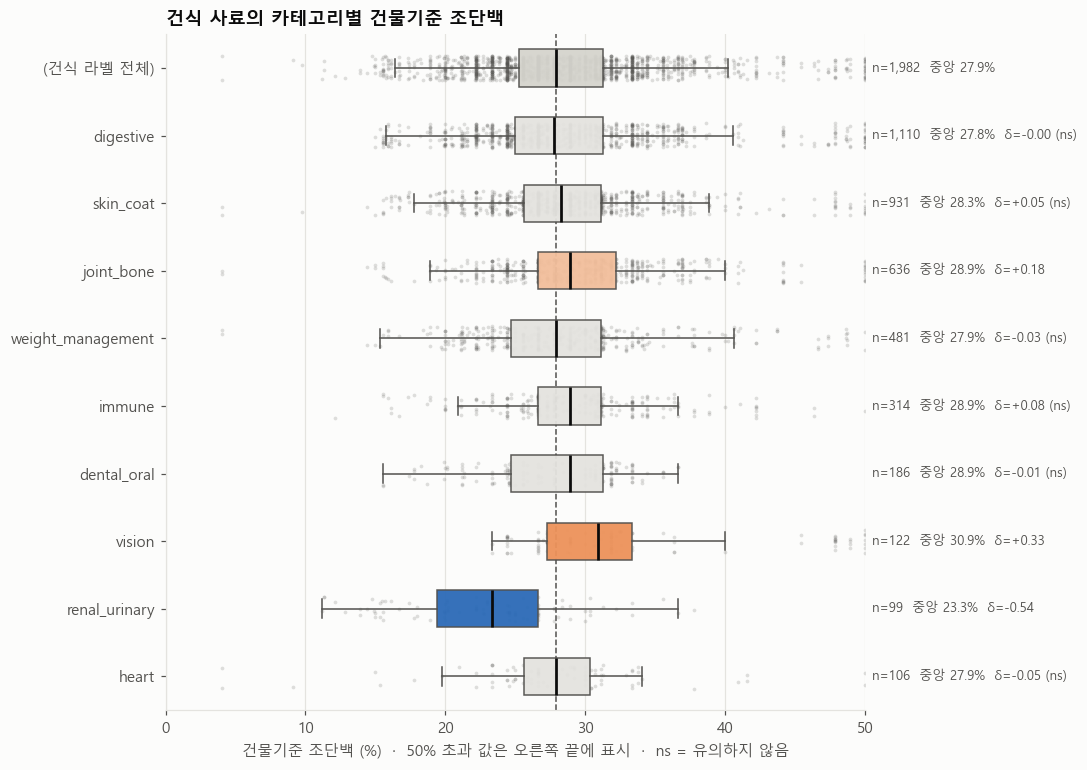

In [39]:
plot_category_nutrient("조단백")

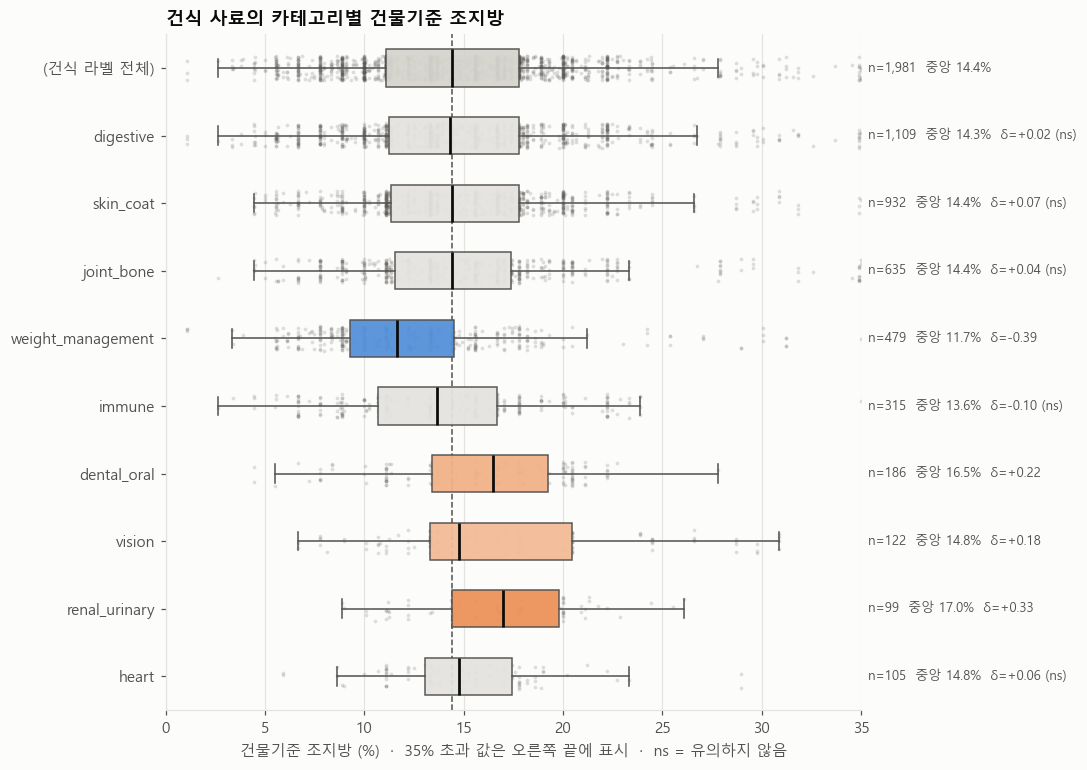

In [40]:
plot_category_nutrient("조지방")

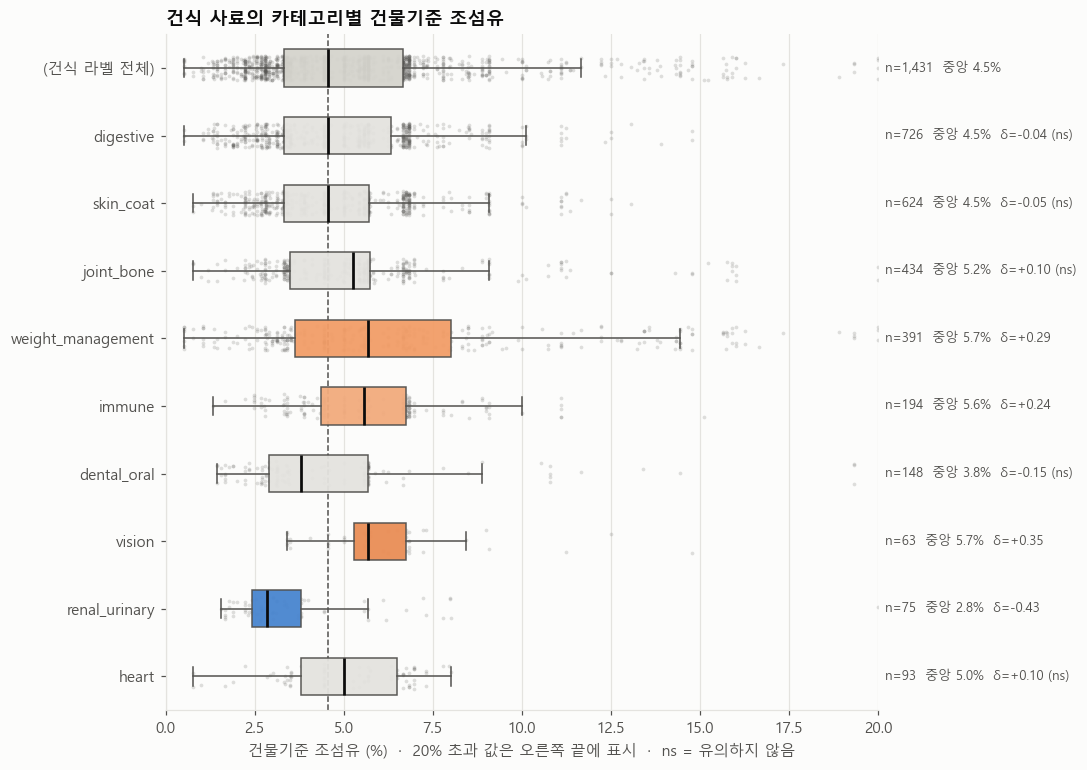

In [41]:
plot_category_nutrient("조섬유")

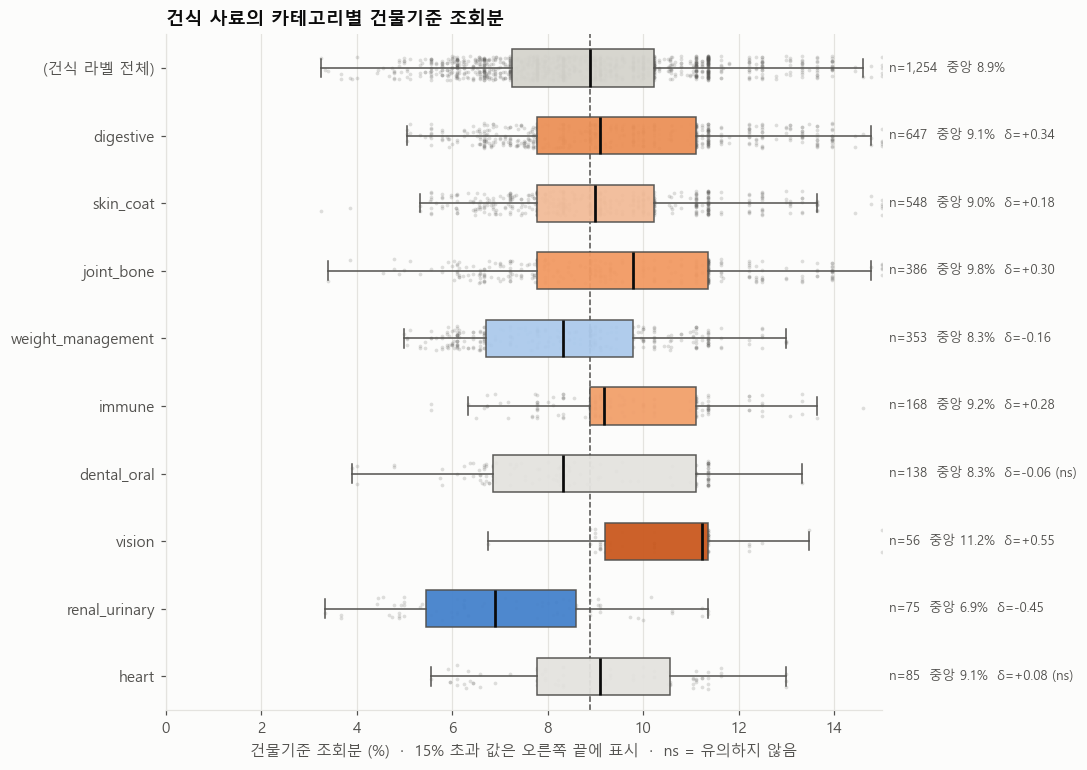

In [42]:
plot_category_nutrient("조회분")

### 5-2. 효과크기 한눈에 보기

행 = 카테고리, 열 = 성분, 색 = Cliff's δ다. 칸 안의 숫자는 δ와 중앙값 차이(%p)이고, 유의하지 않은 칸은 흐리게 표시했다.

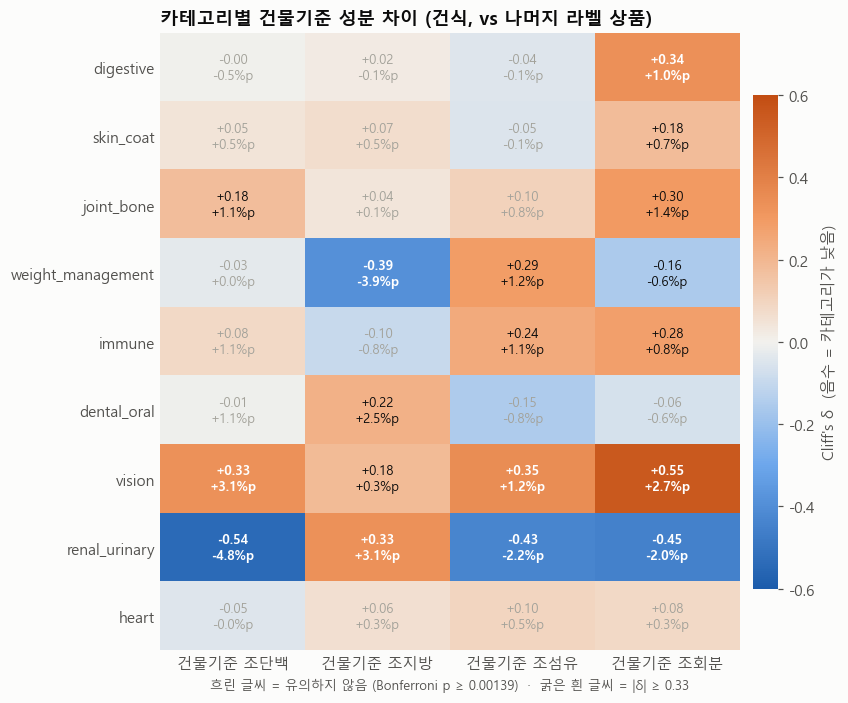

In [43]:
def plot_effect_heatmap(value_col, title, fname, note):
    pivot = lambda col: eff.pivot(index="카테고리", columns="성분", values=col).loc[adopted, NUTS]
    mat, sig, diff = pivot(value_col), pivot("유의"), pivot("중앙값차_%p")
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(adopted) + 2))
    im = ax.imshow(mat.to_numpy(dtype=float), cmap=DIV, vmin=-D_LIM, vmax=D_LIM, aspect="auto")
    for i, c in enumerate(adopted):
        for j, n in enumerate(NUTS):
            d = mat.at[c, n]
            if pd.isna(d):
                ax.text(j, i, "비교 불가", ha="center", va="center", fontsize=8, color=INK2)
                continue
            strong = abs(d) >= 0.33
            text = f"{d:+.2f}"
            if value_col == "효과크기":
                text += f"\n{diff.at[c, n]:+.1f}%p"
            faint = value_col == "효과크기" and not sig.at[c, n]
            ax.text(j, i, text, ha="center", va="center", fontsize=8.5, linespacing=1.3,
                    color="white" if strong else ("#a3a29a" if faint else INK),
                    fontweight="bold" if strong else "normal")
    ax.set_xticks(range(len(NUTS)), [f"건물기준 {n}" for n in NUTS])
    ax.set_yticks(range(len(adopted)), adopted)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    cb.set_label("Cliff's δ  (음수 = 카테고리가 낮음)", color=INK2)
    cb.outline.set_visible(False)
    ax.set_title(title)
    ax.set_xlabel(note, fontsize=8.5)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

plot_effect_heatmap("효과크기", "카테고리별 건물기준 성분 차이 (건식, vs 나머지 라벨 상품)", "category_dm_effect_heatmap.png",
                    f"흐린 글씨 = 유의하지 않음 (Bonferroni p ≥ {ALPHA:.5f})  ·  굵은 흰 글씨 = |δ| ≥ 0.33")

**효과크기 해석표:** 위 히트맵의 δ를 말로 바꾼 표다. 방향은 δ의 부호(+ 높다, − 낮다), 정도는 |δ| 기준이다.

| \|δ\| | 해석 | 표기 |
| --- | --- | --- |
| 0.147 미만 | 무시할 수준 | 미세하게 높다 / 낮다 |
| 0.147 이상 0.33 미만 | 작은 차이 | 약간 높다 / 낮다 |
| 0.33 이상 0.474 미만 | 중간 차이 | 높다 / 낮다 |
| 0.474 이상 | 큰 차이 | 아주 높다 / 낮다 |

칸의 형식은 `표기 (δ)`이고, Bonferroni 기준으로 유의하지 않은 칸에는 `ns`를 붙였다.

In [44]:
DEGREE = ["미세하게", "약간", "", "아주"]  # 무시할 수준 · 작은 · 중간 · 큰 차이

def describe_effect(row):
    level = np.searchsorted([0.147, 0.33, 0.474], abs(row["효과크기"]), side="right")
    word = f"{DEGREE[level]} {'높다' if row['효과크기'] >= 0 else '낮다'}".strip()
    return f"{word} ({row['효과크기']:+.2f})" + ("" if row["유의"] else " ns")

effect_words = (eff.assign(해석=eff.apply(describe_effect, axis=1))
                .pivot(index="카테고리", columns="성분", values="해석").loc[adopted, NUTS])
effect_words.columns = [f"건물기준 {n}" for n in NUTS]
effect_words

,건물기준 조단백,건물기준 조지방,건물기준 조섬유,건물기준 조회분
카테고리,,,,
digestive,미세하게 낮다 (-0.00) ns,미세하게 높다 (+0.02) ns,미세하게 낮다 (-0.04) ns,높다 (+0.34)
skin_coat,미세하게 높다 (+0.05) ns,미세하게 높다 (+0.07) ns,미세하게 낮다 (-0.05) ns,약간 높다 (+0.18)
joint_bone,약간 높다 (+0.18),미세하게 높다 (+0.04) ns,미세하게 높다 (+0.10) ns,약간 높다 (+0.30)
weight_management,미세하게 낮다 (-0.03) ns,낮다 (-0.39),약간 높다 (+0.29),약간 낮다 (-0.16)
immune,미세하게 높다 (+0.08) ns,미세하게 낮다 (-0.10) ns,약간 높다 (+0.24),약간 높다 (+0.28)
dental_oral,미세하게 낮다 (-0.01) ns,약간 높다 (+0.22),약간 낮다 (-0.15) ns,미세하게 낮다 (-0.06) ns
vision,높다 (+0.33),약간 높다 (+0.18),높다 (+0.35),아주 높다 (+0.55)
renal_urinary,아주 낮다 (-0.54),높다 (+0.33),낮다 (-0.43),낮다 (-0.45)
heart,미세하게 낮다 (-0.05) ns,미세하게 높다 (+0.06) ns,미세하게 높다 (+0.10) ns,미세하게 높다 (+0.08) ns


### 5-3. 출처를 통제해도 차이가 남는가

카테고리 차이가 실제로는 출처 차이일 수 있다. 예를 들어 vision은 상품 거의 전부가 다나와다.
아래는 **같은 출처 안에서만** 비교한 δ를 출처별 상품 수로 가중평균한 값이다. 출처 안에서 양쪽 모두 10개 이상인 출처만 쓴다.
5-2와 색이 비슷하면 출처 때문이 아니라 카테고리 자체의 차이다.

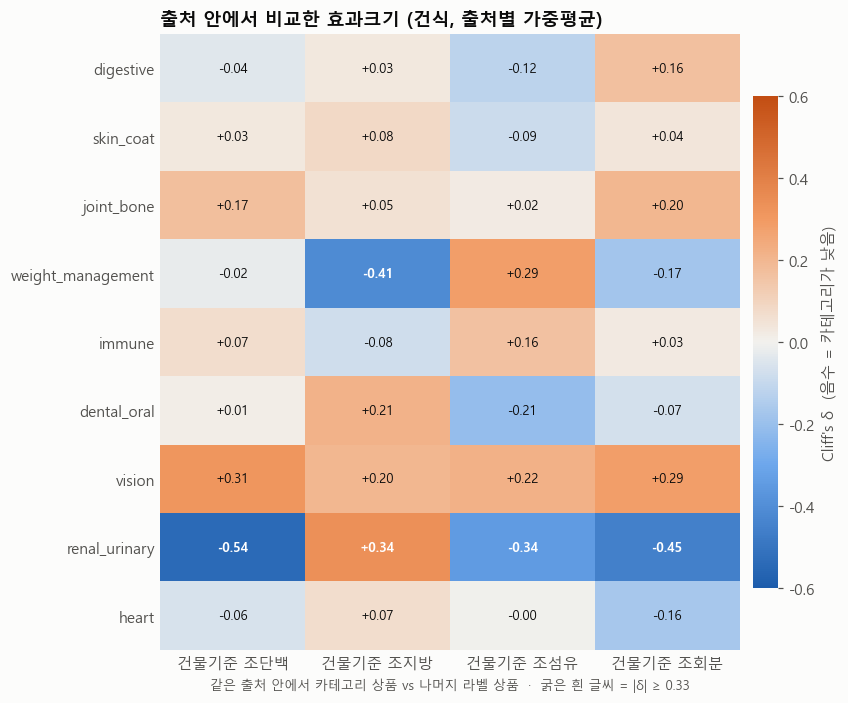

In [45]:
plot_effect_heatmap("출처내_효과크기", "출처 안에서 비교한 효과크기 (건식, 출처별 가중평균)",
                    "category_dm_effect_within_source.png",
                    "같은 출처 안에서 카테고리 상품 vs 나머지 라벨 상품  ·  굵은 흰 글씨 = |δ| ≥ 0.33")

In [46]:
# 표: 전체 δ와 출처 안 δ의 차이가 큰 조합 (출처 효과가 섞였을 가능성)
gap = eff.assign(차이=(eff["효과크기"] - eff["출처내_효과크기"]).abs())
gap.sort_values("차이", ascending=False).head(8)[
    ["카테고리", "성분", "효과크기", "출처내_효과크기", "비교출처수", "차이"]].round(2)

,카테고리,성분,효과크기,출처내_효과크기,비교출처수,차이
27,vision,조회분,0.55,0.29,1,0.26
19,immune,조회분,0.28,0.03,2,0.25
35,heart,조회분,0.08,-0.16,1,0.24
3,digestive,조회분,0.34,0.16,3,0.17
7,skin_coat,조회분,0.18,0.04,3,0.14
26,vision,조섬유,0.35,0.22,1,0.13
11,joint_bone,조회분,0.30,0.20,2,0.10
34,heart,조섬유,0.10,-0.00,1,0.10


### 5-4. 관찰

**결론: 성분 차이가 뚜렷한 카테고리와 거의 없는 카테고리로 나뉜다.** 36개 조합 중 18개가 유의하고 효과가 '작음' 이상이며, 9개는 '중간' 이상이다.

**뚜렷한 차이 (출처를 통제해도 유지)**
- **renal_urinary: 단백질↓, 섬유↓, 회분↓, 지방↑.** 조단백 중앙값 23.3% vs 나머지 28.1% (−4.8%p, δ = −0.54)다. 무작위로 renal_urinary 상품 하나와 나머지 상품 하나를 뽑으면 renal_urinary 쪽 단백질이 더 낮을 확률이 약 77%다. 조섬유 2.8% vs 5.0% (δ = −0.43), 조회분 6.9% vs 8.9% (δ = −0.45), 조지방 17.0% vs 14.0% (δ = +0.33). 단백질·인(회분)을 줄이고 지방으로 열량을 채우는 **신장·요로 처방식의 설계와 일치**한다. 네 성분 모두 효과가 '중간' 이상인 유일한 카테고리다.
- **weight_management: 지방↓, 섬유↑.** 조지방 11.7% vs 15.6% (−3.9%p, δ = −0.39), 조섬유 5.7% vs 4.4% (δ = +0.29). 열량을 줄이고 포만감을 높이는 **체중관리 사료의 설계와 일치**한다.
- 두 카테고리는 같은 출처 안에서 비교해도 δ가 거의 같다 (5-3). 출처 차이가 아니라 카테고리 자체의 차이다.

**작거나 해석에 주의가 필요한 차이**
- **joint_bone:** 조단백(+1.1%p, δ = +0.18)과 조회분(+1.4%p, δ = +0.30)이 약간 높다. 출처 안에서도 +0.17, +0.20으로 남는다.
- **dental_oral:** 조지방이 2.5%p 높다 (δ = +0.22). 효과는 작다.
- **vision:** 네 성분 모두 높게 나오지만 **상품 119/124개가 다나와**라 출처 안 비교도 다나와 하나뿐이다. 소수 브랜드의 제품군이 몰려 생긴 차이일 수 있어 원문 확인이 필요하다.
- **immune·digestive·skin_coat의 조회분 차이는 대부분 출처 효과다.** 전체 δ는 +0.28·+0.34·+0.18이지만, 출처 안에서는 +0.03·+0.16·+0.04로 줄어든다. 출처마다 회분 표기율과 수준이 다르기 때문으로 보인다.

**차이가 거의 없음**
- **digestive(1,110개)·skin_coat(931개)·heart(106개)는 네 성분 모두 차이가 무시할 수준이다** (출처 안 |δ| ≤ 0.16). 특히 상품 수가 가장 많은 두 카테고리가 여기에 속한다.
- 소화·피모 기능은 거시 영양소 비율보다 **원료(프로바이오틱스·프리바이오틱스·오메가-3·어유 등)** 로 구현되는 경우가 많기 때문으로 보인다.

**모델링에 주는 시사점**
- 거시 영양소 4개만으로는 renal_urinary·weight_management 정도만 구분할 수 있다. digestive·skin_coat를 예측하려면 **원료 텍스트와 보조 성분 피처**가 필요하다.
- 따라서 "성분 차이가 없으면 망한다"는 걱정은 절반만 맞다. 성분은 일부 카테고리의 강한 신호이고, 나머지는 원료 피처가 맡아야 한다. 다음 EDA는 **카테고리별 원료 출현 빈도**가 적절하다.